In [3]:
%pip install -q transformers sentencepiece

Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch
import transformers
import pandas as pd
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Transformers: 5.16.1
Pandas: 2.3.3
Scikit-learn: 1.6.1
GPU: Tesla T4


In [5]:
from pathlib import Path
import pandas as pd

# Search Kaggle's input directory for the split files
root = Path("/kaggle/input")

for filename in ["train.csv", "validation.csv", "test.csv"]:
    matches = list(root.rglob(filename))
    print(f"\n{filename}:")
    if matches:
        for path in matches:
            print(" ", path)
    else:
        print("  NOT FOUND — upload or attach the dataset")


train.csv:
  /kaggle/input/datasets/s0ulraag/protein-set/train.csv

validation.csv:
  /kaggle/input/datasets/s0ulraag/protein-set/validation.csv

test.csv:
  /kaggle/input/datasets/s0ulraag/protein-set/test.csv


In [6]:

import pandas as pd

TRAIN_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/train.csv"
VAL_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/validation.csv"
TEST_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/test.csv"

# Load training and validation only for now
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nTraining labels:")
print(train_df["label"].value_counts().sort_index())

print("\nSequence examples:")
print(train_df["Sequence"].head().map(lambda s: str(s)[:60]))


Training shape: (1757, 35)
Validation shape: (377, 35)

Columns:
['Entry', 'Entry Name', 'Protein names', 'Organism', 'Organism (ID)', 'Length', 'Sequence', 'EC number', 'Annotation', 'Protein existence', 'GO', 'Gene Ontology (molecular function)', 'Gene Ontology (biological process)', 'Gene Ontology (cellular component)', 'retrieval_query', 'retrieval_ec_class', 'retrieval_timestamp_utc', 'source_url', 'Annotation score', 'complete_ec_numbers', 'top_level_classes', 'n_top_level_classes', 'label', 'annotation_class_status', 'retrieval_class_matches_annotation', 'sequence_clean', 'sequence_length_actual', 'ambiguous_residue_count', 'invalid_residue_count', 'has_invalid_characters', 'is_empty_sequence', 'exact_sequence_hash', 'is_exact_duplicate', 'length_matches_annotation', 'cluster_id']

Training labels:
label
1    253
2    263
3    203
4    246
5    252
6    282
7    258
Name: count, dtype: int64

Sequence examples:
0    MAGQHLPVPRLEGVSREQFMQHLYPQRKPLVLEGIDLGPCTSKWTV...
1    MAGAENWP

In [7]:

import torch
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "facebook/esm2_t12_35M_UR50D"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Loading ESM-2 model...")
esm_model = AutoModel.from_pretrained(MODEL_NAME)
esm_model = esm_model.to(DEVICE)
esm_model.eval()

print("Model loaded successfully.")
print("Device:", DEVICE)
print("Hidden size:", esm_model.config.hidden_size)
print("Maximum positions:", esm_model.config.max_position_embeddings)


Loading tokenizer...


config.json:   0%|          | 0.00/778 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  136MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Device: cuda
Hidden size: 480
Maximum positions: 1026


In [8]:

import torch
import numpy as np

sequence = str(train_df.iloc[0]["Sequence"]).strip().upper()

inputs = tokenizer(
    sequence,
    return_tensors="pt",
    truncation=True,
    max_length=1022
)

inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

with torch.no_grad():
    outputs = esm_model(**inputs)

# Exclude the beginning and end special tokens.
token_count = int(inputs["attention_mask"][0].sum().item())
amino_acid_embeddings = outputs.last_hidden_state[0, 1:token_count - 1]

# Average the amino-acid representations into one protein vector.
protein_embedding = amino_acid_embeddings.mean(dim=0)

print("Sequence length:", len(sequence))
print("Tokens processed:", token_count)
print("Embedding shape:", tuple(protein_embedding.shape))
print("All values finite:", torch.isfinite(protein_embedding).all().item())
print("First 10 values:", protein_embedding[:10].cpu().numpy())


Sequence length: 315
Tokens processed: 317
Embedding shape: (480,)
All values finite: True
First 10 values: [-0.05334548 -0.00994546 -0.02505838  0.12698635 -0.006244   -0.03067576
  0.1193812   0.09743606 -0.19898157 -0.06725087]


In [9]:

import pandas as pd
import numpy as np

def sequence_length_report(df, name):
    lengths = df["Sequence"].astype(str).str.strip().str.len()

    print(f"\n{name} sequence-length report")
    print("-" * 40)
    print("Number of sequences:", len(lengths))
    print("Minimum length:", lengths.min())
    print("Median length:", lengths.median())
    print("Mean length:", round(lengths.mean(), 2))
    print("95th percentile:", lengths.quantile(0.95))
    print("99th percentile:", lengths.quantile(0.99))
    print("Maximum length:", lengths.max())
    print("Sequences longer than 1022:", (lengths > 1022).sum())
    print("Empty sequences:", (lengths == 0).sum())

    return lengths

train_lengths = sequence_length_report(train_df, "TRAIN")
val_lengths = sequence_length_report(val_df, "VALIDATION")



TRAIN sequence-length report
----------------------------------------
Number of sequences: 1757
Minimum length: 37
Median length: 529.0
Mean length: 620.81
95th percentile: 1410.3999999999987
99th percentile: 1612.0
Maximum length: 1957
Sequences longer than 1022: 261
Empty sequences: 0

VALIDATION sequence-length report
----------------------------------------
Number of sequences: 377
Minimum length: 150
Median length: 472.0
Mean length: 594.51
95th percentile: 1282.0
99th percentile: 1545.6000000000017
Maximum length: 1816
Sequences longer than 1022: 54
Empty sequences: 0


In [10]:

WINDOW_SIZE = 1000
OVERLAP = 200
STRIDE = WINDOW_SIZE - OVERLAP

def count_windows(length):
    if length <= WINDOW_SIZE:
        return 1
    return 1 + int(np.ceil((length - WINDOW_SIZE) / STRIDE))

for name, lengths in [
    ("Training", train_lengths),
    ("Validation", val_lengths)
]:
    windows = lengths.apply(count_windows)

    print(f"\n{name}")
    print("Proteins:", len(lengths))
    print("Proteins needing multiple windows:", (lengths > WINDOW_SIZE).sum())
    print("Total windows:", windows.sum())
    print("Maximum windows for one protein:", windows.max())



Training
Proteins: 1757
Proteins needing multiple windows: 272
Total windows: 2033
Maximum windows for one protein: 3

Validation
Proteins: 377
Proteins needing multiple windows: 60
Total windows: 438
Maximum windows for one protein: 3


In [11]:

from pathlib import Path
import numpy as np
import torch
import time
import json

# Settings
WINDOW_SIZE = 1000
OVERLAP = 200
STRIDE = WINDOW_SIZE - OVERLAP
BATCH_SIZE = 4  # conservative starting point for a 15.6 GB T4

OUTPUT_DIR = Path("/kaggle/working/esm2_embeddings")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def make_windows(sequence):
    sequence = str(sequence).strip().upper()
    if not sequence:
        raise ValueError("Encountered an empty protein sequence.")

    if len(sequence) <= WINDOW_SIZE:
        return [(0, sequence)]

    windows = []
    start = 0
    while start < len(sequence):
        chunk = sequence[start:start + WINDOW_SIZE]
        windows.append((start, chunk))
        if start + WINDOW_SIZE >= len(sequence):
            break
        start += STRIDE

    return windows


def embed_dataframe(df, split_name):
    sequences = df["Sequence"].astype(str).str.strip().str.upper().tolist()
    all_windows = []
    window_map = []

    # Record each window's protein and start position.
    for protein_idx, sequence in enumerate(sequences):
        windows = make_windows(sequence)
        for start, chunk in windows:
            window_map.append((protein_idx, start, len(chunk)))
            all_windows.append(chunk)

    # Store residue vectors per protein. Each residue is counted once.
    residue_sums = [None] * len(sequences)
    residue_counts = [None] * len(sequences)

    started = time.time()
    esm_model.eval()

    for batch_start in range(0, len(all_windows), BATCH_SIZE):
        batch_end = min(batch_start + BATCH_SIZE, len(all_windows))
        batch_sequences = all_windows[batch_start:batch_end]

        encoded = tokenizer(
            batch_sequences,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=WINDOW_SIZE + 2
        )
        encoded = {k: v.to(DEVICE) for k, v in encoded.items()}

        with torch.inference_mode():
            hidden = esm_model(**encoded).last_hidden_state

        attention = encoded["attention_mask"]

        for local_idx, global_idx in enumerate(range(batch_start, batch_end)):
            protein_idx, start, chunk_len = window_map[global_idx]

            # Extract amino-acid tokens only, excluding special tokens.
            token_vectors = hidden[local_idx, 1:chunk_len + 1].float().cpu().numpy()

            if residue_sums[protein_idx] is None:
                residue_sums[protein_idx] = np.zeros(
                    (len(sequences[protein_idx]), esm_model.config.hidden_size),
                    dtype=np.float64
                )
                residue_counts[protein_idx] = np.zeros(
                    len(sequences[protein_idx]), dtype=np.float32
                )

            end = start + chunk_len
            residue_sums[protein_idx][start:end] += token_vectors
            residue_counts[protein_idx][start:end] += 1

        if batch_end % 100 == 0 or batch_end == len(all_windows):
            print(f"{split_name}: processed {batch_end}/{len(all_windows)} windows")

    embeddings = []
    for i, sequence in enumerate(sequences):
        counts = residue_counts[i]
        if counts is None or np.any(counts == 0):
            raise RuntimeError(f"Some residues were not embedded in protein index {i}.")
        per_residue = residue_sums[i] / counts[:, None]
        embeddings.append(per_residue.mean(axis=0).astype(np.float32))

    embeddings = np.vstack(embeddings)

    output_file = OUTPUT_DIR / f"{split_name}_embeddings.npz"
    np.savez_compressed(
        output_file,
        embeddings=embeddings,
        labels=df["label"].to_numpy(),
        entries=df["Entry"].astype(str).to_numpy()
    )

    elapsed = time.time() - started
    print(f"\n{split_name} complete")
    print("Embedding matrix:", embeddings.shape)
    print("Elapsed seconds:", round(elapsed, 1))
    print("Saved to:", output_file)

    return embeddings


train_embeddings = embed_dataframe(train_df, "train")
val_embeddings = embed_dataframe(val_df, "validation")

print("\nAll embeddings generated.")
print("Train:", train_embeddings.shape)
print("Validation:", val_embeddings.shape)
print("Output directory:", OUTPUT_DIR)


train: processed 100/2033 windows
train: processed 200/2033 windows
train: processed 300/2033 windows
train: processed 400/2033 windows
train: processed 500/2033 windows
train: processed 600/2033 windows
train: processed 700/2033 windows
train: processed 800/2033 windows
train: processed 900/2033 windows
train: processed 1000/2033 windows
train: processed 1100/2033 windows
train: processed 1200/2033 windows
train: processed 1300/2033 windows
train: processed 1400/2033 windows
train: processed 1500/2033 windows
train: processed 1600/2033 windows
train: processed 1700/2033 windows
train: processed 1800/2033 windows
train: processed 1900/2033 windows
train: processed 2000/2033 windows
train: processed 2033/2033 windows

train complete
Embedding matrix: (1757, 480)
Elapsed seconds: 78.3
Saved to: /kaggle/working/esm2_embeddings/train_embeddings.npz
validation: processed 100/438 windows
validation: processed 200/438 windows
validation: processed 300/438 windows
validation: processed 400/438

Training: (1757, 480) (1757,)
Validation: (377, 480) (377,)

Training Logistic Regression...

Metrics:
model: Logistic Regression
accuracy: 0.6419
balanced_accuracy: 0.6342
macro_f1: 0.6333
weighted_f1: 0.6373

Classification report:
              precision    recall  f1-score   support

           1       0.61      0.77      0.68        60
           2       0.67      0.81      0.73        64
           3       0.56      0.68      0.62        41
           4       0.40      0.36      0.38        55
           5       0.58      0.42      0.49        52
           6       0.81      0.81      0.81        57
           7       0.97      0.58      0.73        48

    accuracy                           0.64       377
   macro avg       0.66      0.63      0.63       377
weighted avg       0.65      0.64      0.64       377



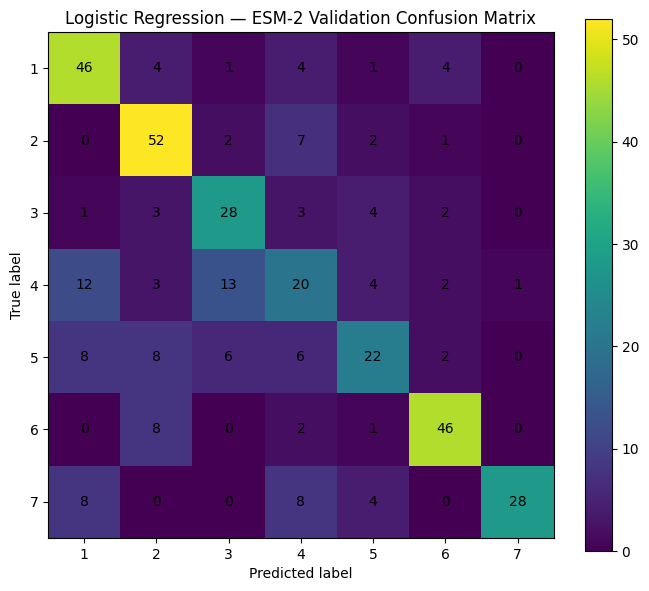


Training Linear SVM...

Metrics:
model: Linear SVM
accuracy: 0.6525
balanced_accuracy: 0.6443
macro_f1: 0.6399
weighted_f1: 0.6441

Classification report:
              precision    recall  f1-score   support

           1       0.57      0.73      0.64        60
           2       0.64      0.86      0.73        64
           3       0.53      0.66      0.59        41
           4       0.54      0.36      0.43        55
           5       0.62      0.40      0.49        52
           6       0.84      0.82      0.83        57
           7       0.89      0.67      0.76        48

    accuracy                           0.65       377
   macro avg       0.66      0.64      0.64       377
weighted avg       0.66      0.65      0.64       377



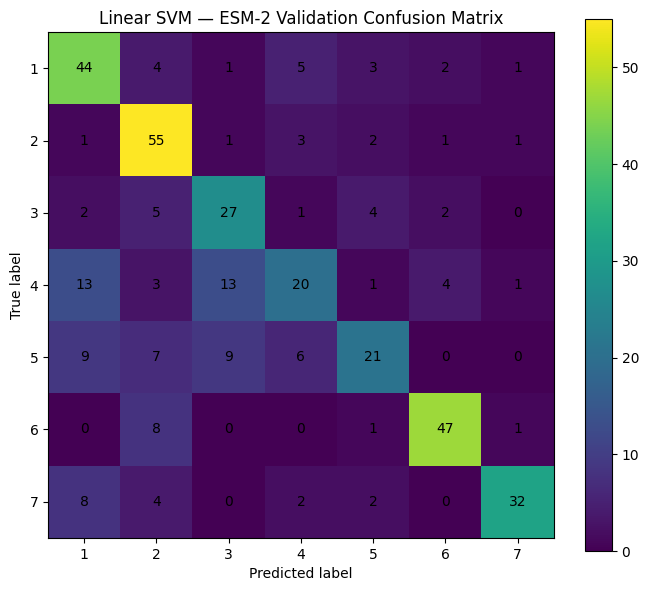


MODEL COMPARISON — ranked by validation macro-F1
              model  accuracy  balanced_accuracy  macro_f1  weighted_f1
         Linear SVM   0.65252           0.644279  0.639935     0.644123
Logistic Regression   0.64191           0.634165  0.633342     0.637338

Saved results to: /kaggle/working/esm2_results
Held-out test set remains untouched.


In [12]:

import numpy as np
import pandas as pd
import json
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("/kaggle/working/esm2_embeddings")
RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load cached embeddings and labels
train_data = np.load(OUTPUT_DIR / "train_embeddings.npz")
val_data = np.load(OUTPUT_DIR / "validation_embeddings.npz")

X_train = train_data["embeddings"]
y_train = train_data["labels"].astype(int)

X_val = val_data["embeddings"]
y_val = val_data["labels"].astype(int)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    ),
    "Linear SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    )
}

results = []
reports = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_val, predictions),
        "macro_f1": f1_score(y_val, predictions, average="macro"),
        "weighted_f1": f1_score(y_val, predictions, average="weighted")
    }
    results.append(metrics)

    reports[name] = classification_report(
        y_val, predictions, output_dict=True, zero_division=0
    )

    print("\nMetrics:")
    for key, value in metrics.items():
        print(f"{key}: {value:.4f}" if isinstance(value, float)
              else f"{key}: {value}")

    print("\nClassification report:")
    print(classification_report(y_val, predictions, zero_division=0))

    # Save confusion matrix for each model
    cm = confusion_matrix(y_val, predictions, labels=[1, 2, 3, 4, 5, 6, 7])
    pd.DataFrame(
        cm,
        index=[f"True_{i}" for i in range(1, 8)],
        columns=[f"Pred_{i}" for i in range(1, 8)]
    ).to_csv(RESULTS_DIR / f"{name.lower().replace(' ', '_')}_confusion_matrix.csv")

    # Save plot
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{name} — ESM-2 Validation Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(7), range(1, 8))
    ax.set_yticks(range(7), range(1, 8))

    for i in range(7):
        for j in range(7):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(
        RESULTS_DIR / f"{name.lower().replace(' ', '_')}_confusion_matrix.png",
        dpi=160
    )
    plt.show()
    plt.close(fig)

results_df = pd.DataFrame(results).sort_values(
    "macro_f1", ascending=False
)
results_df.to_csv(RESULTS_DIR / "validation_model_comparison.csv", index=False)

with open(RESULTS_DIR / "classification_reports.json", "w") as f:
    json.dump(reports, f, indent=2)

print("\nMODEL COMPARISON — ranked by validation macro-F1")
print(results_df.to_string(index=False))
print("\nSaved results to:", RESULTS_DIR)
print("Held-out test set remains untouched.")


In [13]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd
import json
from pathlib import Path

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")
RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_data = __import__("numpy").load(EMBED_DIR / "train_embeddings.npz")
val_data = __import__("numpy").load(EMBED_DIR / "validation_embeddings.npz")

X_train = train_data["embeddings"]
y_train = train_data["labels"].astype(int)
X_val = val_data["embeddings"]
y_val = val_data["labels"].astype(int)

results = []
models = {}

for c_value in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    model = make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=c_value,
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    row = {
        "C": c_value,
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_val, predictions),
        "macro_f1": f1_score(y_val, predictions, average="macro"),
        "weighted_f1": f1_score(y_val, predictions, average="weighted")
    }

    results.append(row)
    models[c_value] = model

results_df = pd.DataFrame(results).sort_values(
    "macro_f1", ascending=False
)

results_df.to_csv(
    RESULTS_DIR / "esm2_svm_c_tuning.csv",
    index=False
)

print(results_df.to_string(index=False))

best_c = float(results_df.iloc[0]["C"])
print(f"\nBest C by validation macro-F1: {best_c}")
print("Best validation macro-F1:",
      round(float(results_df.iloc[0]["macro_f1"]), 4))

with open(RESULTS_DIR / "esm2_svm_tuning_summary.json", "w") as f:
    json.dump({
        "selection_metric": "validation_macro_f1",
        "best_C": best_c,
        "best_validation_macro_f1":
            float(results_df.iloc[0]["macro_f1"]),
        "test_set_used": False,
        "all_results": results
    }, f, indent=2)

print("Tuning results saved to:", RESULTS_DIR)
print("Held-out test set remains untouched.")


    C  accuracy  balanced_accuracy  macro_f1  weighted_f1
 2.00  0.660477           0.652247  0.646287     0.650582
 0.10  0.655172           0.647468  0.644231     0.648349
 5.00  0.655172           0.645700  0.640132     0.645407
 1.00  0.652520           0.644279  0.639935     0.644123
 0.50  0.652520           0.644279  0.639935     0.644123
10.00  0.649867           0.640975  0.634240     0.638962
 0.01  0.641910           0.632661  0.632870     0.638674

Best C by validation macro-F1: 2.0
Best validation macro-F1: 0.6463
Tuning results saved to: /kaggle/working/esm2_results
Held-out test set remains untouched.


In [14]:

from pathlib import Path
import json

results_dir = Path("/kaggle/working/esm2_results")
results_dir.mkdir(parents=True, exist_ok=True)

selected_model = {
    "experiment": "ESM-2 embeddings + Linear SVM",
    "embedding_model": "facebook/esm2_t12_35M_UR50D",
    "embedding_dimension": 480,
    "classifier": "LinearSVC",
    "selected_C": 2.0,
    "class_weight": "balanced",
    "selection_metric": "validation_macro_f1",
    "validation_accuracy": 0.660477,
    "validation_balanced_accuracy": 0.652247,
    "validation_macro_f1": 0.646287,
    "validation_weighted_f1": 0.650582,
    "training_records": 1757,
    "validation_records": 377,
    "test_set_used_for_selection": False,
    "random_state": 42
}

output_path = results_dir / "selected_esm2_svm_config.json"

with open(output_path, "w") as f:
    json.dump(selected_model, f, indent=2)

print("Selected model configuration saved:")
print(output_path)
print(json.dumps(selected_model, indent=2))


Selected model configuration saved:
/kaggle/working/esm2_results/selected_esm2_svm_config.json
{
  "experiment": "ESM-2 embeddings + Linear SVM",
  "embedding_model": "facebook/esm2_t12_35M_UR50D",
  "embedding_dimension": 480,
  "classifier": "LinearSVC",
  "selected_C": 2.0,
  "class_weight": "balanced",
  "selection_metric": "validation_macro_f1",
  "validation_accuracy": 0.660477,
  "validation_balanced_accuracy": 0.652247,
  "validation_macro_f1": 0.646287,
  "validation_weighted_f1": 0.650582,
  "training_records": 1757,
  "validation_records": 377,
  "test_set_used_for_selection": false,
  "random_state": 42
}


In [15]:

from pathlib import Path
import numpy as np

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")

for name in ["train", "validation", "test"]:
    path = EMBED_DIR / f"{name}_embeddings.npz"
    if not path.exists():
        print(f"MISSING: {path}")
    else:
        data = np.load(path)
        print(
            f"{name}: embeddings={data['embeddings'].shape}, "
            f"labels={data['labels'].shape}"
        )


train: embeddings=(1757, 480), labels=(1757,)
validation: embeddings=(377, 480), labels=(377,)
MISSING: /kaggle/working/esm2_embeddings/test_embeddings.npz


In [16]:
print("Model loaded:", "model" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())
print("Test dataframe loaded:", "test_df" in globals())
print("Window function names:",
      [name for name in globals()
       if "window" in name.lower() and callable(globals()[name])])

Model loaded: True
Tokenizer loaded: True
Test dataframe loaded: False
Window function names: ['count_windows', 'make_windows']


In [17]:
import pandas as pd

TEST_PATH = "/kaggle/input/datasets/s0ulraag/protein-set/test.csv"
test_df = pd.read_csv(TEST_PATH)

print("Test shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
print(test_df[["Entry", "Sequence", "label"]].head())

Test shape: (539, 35)
Columns: ['Entry', 'Entry Name', 'Protein names', 'Organism', 'Organism (ID)', 'Length', 'Sequence', 'EC number', 'Annotation', 'Protein existence', 'GO', 'Gene Ontology (molecular function)', 'Gene Ontology (biological process)', 'Gene Ontology (cellular component)', 'retrieval_query', 'retrieval_ec_class', 'retrieval_timestamp_utc', 'source_url', 'Annotation score', 'complete_ec_numbers', 'top_level_classes', 'n_top_level_classes', 'label', 'annotation_class_status', 'retrieval_class_matches_annotation', 'sequence_clean', 'sequence_length_actual', 'ambiguous_residue_count', 'invalid_residue_count', 'has_invalid_characters', 'is_empty_sequence', 'exact_sequence_hash', 'is_exact_duplicate', 'length_matches_annotation', 'cluster_id']
    Entry                                           Sequence  label
0  C9JRZ8  MATFVELSTKAKMPIVGLGTWRSLLGKVKEAVKVAIDAEYRHIDCA...      1
1  O14756  MWLYLAAFVGLYYLLHWYRERQVVSHLQDKYVFITGCDSGFGNLLA...      1
2  O43593  MESTPSFLKGTPTWEKTAPE

In [18]:
import inspect
import torch

print("Window functions:")
print("make_windows:", inspect.signature(make_windows))
print("count_windows:", inspect.signature(count_windows))

print("\nESM-2 model variables:")
for name in ["esm_model", "tokenizer", "model"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__)

print("\nDevice:")
if "esm_model" in globals():
    print(next(esm_model.parameters()).device)
elif "model" in globals() and hasattr(model, "parameters"):
    print(next(model.parameters()).device)
else:
    print("Inspect the model variables above.")

print("\nWindowing constants:")
for name in [
    "MAX_LENGTH", "MAX_TOKENS", "WINDOW_SIZE",
    "WINDOW_STRIDE", "BATCH_SIZE", "device"
]:
    if name in globals():
        print(f"{name} =", globals()[name])

Window functions:
make_windows: (sequence)
count_windows: (length)

ESM-2 model variables:
esm_model -> EsmModel
tokenizer -> EsmTokenizer
model -> Pipeline

Device:
cuda:0

Windowing constants:
WINDOW_SIZE = 1000
BATCH_SIZE = 4


In [19]:
sample_sequence = str(test_df.iloc[0]["Sequence"]).strip().upper()
sample_windows = make_windows(sample_sequence)

print("Sequence length:", len(sample_sequence))
print("Number of windows:", len(sample_windows))
print("Window type:", type(sample_windows[0]))
print("First window preview:", repr(sample_windows[0])[:300])

Sequence length: 316
Number of windows: 1
Window type: <class 'tuple'>
First window preview: (0, 'MATFVELSTKAKMPIVGLGTWRSLLGKVKEAVKVAIDAEYRHIDCAYFYENQHEVGEAIQEKIQEKAVMREDLFIVSKVWPTFFERPLVRKAFEKTLKDLKLSYLDVYLIHWPQGFKTGDDFFPKDDKGNMISGKGTFLDAWEAMEELVDEGLVKALGVSNFNHFQIERLLNKPGLKYKPVTNQVECHPYLTQEKLIQYCHSKGITVTAYSPLGSPDRPWAKPEDPSLLEDPKIKEIAAKHKKTTAQVLIRFHIQRNVTVIPKSMTPAHIVENIQVFDFKLSDEEMATILSFNRN


In [20]:

import numpy as np
import torch
import time
from pathlib import Path

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")
EMBED_DIR.mkdir(parents=True, exist_ok=True)

assert "test_df" in globals(), "Load test_df first."
assert "Sequence" in test_df.columns and "label" in test_df.columns
assert "esm_model" in globals() and "tokenizer" in globals()
assert "make_windows" in globals() and "BATCH_SIZE" in globals()

esm_model.eval()
device = next(esm_model.parameters()).device

all_embeddings = []
all_labels = []
start_time = time.time()

for row_idx, row in test_df.reset_index(drop=True).iterrows():
    sequence = str(row["Sequence"]).strip().upper()
    label = int(row["label"])

    windows = make_windows(sequence)
    if not windows:
        raise ValueError(f"No windows generated for test row {row_idx}")

    # make_windows may return (start_position, sequence_window) tuples.
    batch_windows = [
        w[1] if isinstance(w, tuple) else w
        for w in windows
    ]
    batch_embeddings = []

    for batch_start in range(0, len(batch_windows), BATCH_SIZE):
        batch = batch_windows[batch_start:batch_start + BATCH_SIZE]

        encoded = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=1024
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}

        with torch.inference_mode():
            outputs = esm_model(**encoded)
            hidden = outputs.last_hidden_state

            attention_mask = encoded["attention_mask"].bool()
            special_mask = torch.zeros_like(attention_mask)

            for token_id in tokenizer.all_special_ids:
                special_mask |= encoded["input_ids"].eq(token_id)

            residue_mask = attention_mask & ~special_mask
            mask = residue_mask.unsqueeze(-1).to(hidden.dtype)

            summed = (hidden * mask).sum(dim=1)
            counts = mask.sum(dim=1).clamp(min=1)
            pooled = summed / counts

        batch_embeddings.extend(
            pooled.detach().cpu().numpy().astype(np.float32)
        )

    # One mean embedding per protein, even when it has multiple windows.
    protein_embedding = np.mean(
        np.stack(batch_embeddings, axis=0), axis=0
    )

    all_embeddings.append(protein_embedding)
    all_labels.append(label)

    if (row_idx + 1) % 50 == 0 or row_idx + 1 == len(test_df):
        print(f"Test: processed {row_idx + 1}/{len(test_df)} proteins")

X_test = np.stack(all_embeddings).astype(np.float32)
y_test = np.asarray(all_labels, dtype=np.int64)

assert X_test.shape == (len(test_df), 480), X_test.shape
assert y_test.shape == (len(test_df),)
assert np.isfinite(X_test).all(), "Non-finite embeddings detected."

unique_count = np.unique(X_test, axis=0).shape[0]

print("\nEmbedding integrity check")
print("Shape:", X_test.shape)
print("Unique embedding rows:", unique_count)
print("Standard deviation:", float(X_test.std()))
print("First 5 row norms:", np.linalg.norm(X_test[:5], axis=1))

if unique_count == 1:
    raise RuntimeError(
        "All test embeddings are identical. Do not evaluate the model; "
        "inspect the model outputs and window function."
    )

output_path = EMBED_DIR / "test_embeddings.npz"
np.savez_compressed(
    output_path,
    embeddings=X_test,
    labels=y_test
)

print("\nTest embeddings regenerated and saved.")
print("Elapsed seconds:", round(time.time() - start_time, 2))
print("Saved to:", output_path)


Test: processed 50/539 proteins
Test: processed 100/539 proteins
Test: processed 150/539 proteins
Test: processed 200/539 proteins
Test: processed 250/539 proteins
Test: processed 300/539 proteins
Test: processed 350/539 proteins
Test: processed 400/539 proteins
Test: processed 450/539 proteins
Test: processed 500/539 proteins
Test: processed 539/539 proteins

Embedding integrity check
Shape: (539, 480)
Unique embedding rows: 539
Standard deviation: 0.24880383908748627
First 5 row norms: [4.196405  3.6252546 6.1795044 4.906949  4.5197935]

Test embeddings regenerated and saved.
Elapsed seconds: 18.67
Saved to: /kaggle/working/esm2_embeddings/test_embeddings.npz


FINAL HELD-OUT TEST RESULTS
experiment: ESM-2 + StandardScaler + Linear SVM
selected_C: 2.0
training_records: 2134
test_records: 539
test_accuracy: 0.7142857142857143
test_balanced_accuracy: 0.7111902134101492
test_macro_f1: 0.7034687011919823
test_weighted_f1: 0.7093489887162305
training_seconds: 32.006
test_used_for_model_selection: False
random_state: 42

Classification report:
              precision    recall  f1-score   support

           1       0.63      0.58      0.60        72
           2       0.82      0.82      0.82        85
           3       0.66      0.79      0.72        62
           4       0.56      0.59      0.58        75
           5       0.56      0.43      0.49        81
           6       0.76      0.86      0.81        71
           7       0.90      0.90      0.90        93

    accuracy                           0.71       539
   macro avg       0.70      0.71      0.70       539
weighted avg       0.71      0.71      0.71       539



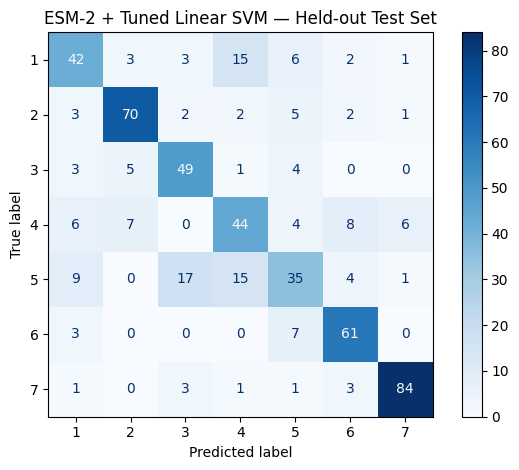


Results saved to: /kaggle/working/esm2_results


In [21]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

EMBED_DIR = Path("/kaggle/working/esm2_embeddings")
RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train = np.load(EMBED_DIR / "train_embeddings.npz")
val = np.load(EMBED_DIR / "validation_embeddings.npz")
test = np.load(EMBED_DIR / "test_embeddings.npz")

X_train, y_train = train["embeddings"], train["labels"].astype(int)
X_val, y_val = val["embeddings"], val["labels"].astype(int)
X_test, y_test = test["embeddings"], test["labels"].astype(int)

assert X_train.shape == (1757, 480)
assert X_val.shape == (377, 480)
assert X_test.shape == (539, 480)
assert np.isfinite(X_test).all()

# Combine training and validation data only.
X_fit = np.concatenate([X_train, X_val], axis=0)
y_fit = np.concatenate([y_train, y_val], axis=0)

final_model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=2.0,
        class_weight="balanced",
        random_state=42,
        max_iter=10000
    )
)

start = time.time()
final_model.fit(X_fit, y_fit)
training_seconds = time.time() - start

# First and only final evaluation on the held-out test set.
y_pred = final_model.predict(X_test)

metrics = {
    "experiment": "ESM-2 + StandardScaler + Linear SVM",
    "selected_C": 2.0,
    "training_records": int(len(y_fit)),
    "test_records": int(len(y_test)),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "test_macro_f1": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "test_weighted_f1": float(
        f1_score(y_test, y_pred, average="weighted")
    ),
    "training_seconds": round(training_seconds, 3),
    "test_used_for_model_selection": False,
    "random_state": 42
}

print("FINAL HELD-OUT TEST RESULTS")
print("=" * 55)
for key, value in metrics.items():
    print(f"{key}: {value}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, labels=list(range(1, 8)), zero_division=0
))

with open(RESULTS_DIR / "final_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

report = classification_report(
    y_test, y_pred, labels=list(range(1, 8)),
    output_dict=True, zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "final_test_classification_report.csv"
)

cm = confusion_matrix(y_test, y_pred, labels=list(range(1, 8)))
pd.DataFrame(
    cm,
    index=[f"True_{i}" for i in range(1, 8)],
    columns=[f"Predicted_{i}" for i in range(1, 8)]
).to_csv(RESULTS_DIR / "final_test_confusion_matrix.csv")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=list(range(1, 8))
)
disp.plot(cmap="Blues", values_format="d")
plt.title("ESM-2 + Tuned Linear SVM — Held-out Test Set")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "final_test_confusion_matrix.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("\nResults saved to:", RESULTS_DIR)


In [22]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Reuse final_model and the arrays from the previous evaluation cell.
splits = {
    "Train": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test),
}

print("=" * 65)
print("1. LABEL DISTRIBUTION")
print("=" * 65)

for name, (_, y) in splits.items():
    print(f"\n{name}:")
    print(pd.Series(y).value_counts().sort_index().to_dict())

print("\n" + "=" * 65)
print("2. EMBEDDING STATISTICS")
print("=" * 65)

for name, (X, _) in splits.items():
    print(f"\n{name}")
    print("Shape:", X.shape)
    print("All finite:", bool(np.isfinite(X).all()))
    print("Mean:", round(float(X.mean()), 6))
    print("Standard deviation:", round(float(X.std()), 6))
    print("Minimum:", round(float(X.min()), 6))
    print("Maximum:", round(float(X.max()), 6))
    print("Mean row norm:", round(float(np.linalg.norm(X, axis=1).mean()), 6))
    print("Unique rows:", len(np.unique(X, axis=0)))

print("\n" + "=" * 65)
print("3. PREDICTIONS ON EACH SPLIT")
print("=" * 65)

for name, (X, y) in splits.items():
    pred = final_model.predict(X)

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y, pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y, pred), 4))
    print("Macro F1:", round(f1_score(y, pred, average="macro"), 4))
    print("Predicted class counts:",
          pd.Series(pred).value_counts().sort_index().to_dict())

print("\n" + "=" * 65)
print("4. MEAN EMBEDDING DISTANCE BETWEEN SPLITS")
print("=" * 65)

for name, (X, _) in splits.items():
    print(
        f"{name}: mean feature vector (first 10 dimensions):",
        np.round(X.mean(axis=0)[:10], 4)
    )

print("\nDiagnostic complete. No model or data files were modified.")


1. LABEL DISTRIBUTION

Train:
{1: 253, 2: 263, 3: 203, 4: 246, 5: 252, 6: 282, 7: 258}

Validation:
{1: 60, 2: 64, 3: 41, 4: 55, 5: 52, 6: 57, 7: 48}

Test:
{1: 72, 2: 85, 3: 62, 4: 75, 5: 81, 6: 71, 7: 93}

2. EMBEDDING STATISTICS

Train
Shape: (1757, 480)
All finite: True
Mean: 0.005231
Standard deviation: 0.238289
Minimum: -2.607493
Maximum: 6.180962
Mean row norm: 5.160276
Unique rows: 1757

Validation
Shape: (377, 480)
All finite: True
Mean: 0.005348
Standard deviation: 0.239837
Minimum: -2.596582
Maximum: 6.010397
Mean row norm: 5.204095
Unique rows: 377

Test
Shape: (539, 480)
All finite: True
Mean: 0.005247
Standard deviation: 0.248804
Minimum: -2.645756
Maximum: 6.223321
Mean row norm: 5.386658
Unique rows: 539

3. PREDICTIONS ON EACH SPLIT

Train
Accuracy: 1.0
Balanced accuracy: 1.0
Macro F1: 1.0
Predicted class counts: {1: 253, 2: 263, 3: 203, 4: 246, 5: 252, 6: 282, 7: 258}

Validation
Accuracy: 1.0
Balanced accuracy: 1.0
Macro F1: 1.0
Predicted class counts: {1: 60, 2: 64,

In [23]:
test = np.load(
    "/kaggle/working/esm2_embeddings/test_embeddings.npz"
)
X_test = test["embeddings"]
y_test = test["labels"]

print("Test embedding shape:", X_test.shape)
print("Unique rows:", np.unique(X_test, axis=0).shape[0])

Test embedding shape: (539, 480)
Unique rows: 539


In [24]:

print("Test rows:", len(test_df))
print("Unique protein sequences:", test_df["Sequence"].nunique())
print("Missing sequences:", test_df["Sequence"].isna().sum())

print("\nFirst 5 sequence lengths:")
print(test_df["Sequence"].astype(str).str.len().head().tolist())

print("\nFirst 3 sequence previews:")
for sequence in test_df["Sequence"].head(3):
    print(str(sequence)[:80])
    print()


Test rows: 539
Unique protein sequences: 539
Missing sequences: 0

First 5 sequence lengths:
[316, 317, 1189, 331, 187]

First 3 sequence previews:
MATFVELSTKAKMPIVGLGTWRSLLGKVKEAVKVAIDAEYRHIDCAYFYENQHEVGEAIQEKIQEKAVMREDLFIVSKVW

MWLYLAAFVGLYYLLHWYRERQVVSHLQDKYVFITGCDSGFGNLLARQLDARGLRVLAACLTEKGAEQLRGQTSDRLETV

MESTPSFLKGTPTWEKTAPENGIVRQEPGSPPRDGLHHGPLCLGEPAPFWRGVLSTPDSWLPPGFPQGPKDMLPLVEGEG



In [25]:

import numpy as np

path = "/kaggle/working/esm2_embeddings/test_embeddings.npz"

with np.load(path) as data:
    print("Stored arrays:", data.files)

    embeddings = data["embeddings"]
    labels = data["labels"]

    print("Embedding shape:", embeddings.shape)
    print("Label shape:", labels.shape)
    print("Unique embedding rows:", np.unique(embeddings, axis=0).shape[0])
    print("First 5 row norms:", np.linalg.norm(embeddings[:5], axis=1))
    print("First 5 label values:", labels[:5])


Stored arrays: ['embeddings', 'labels']
Embedding shape: (539, 480)
Label shape: (539,)
Unique embedding rows: 539
First 5 row norms: [4.196405  3.6252546 6.1795044 4.906949  4.5197935]
First 5 label values: [1 1 1 1 1]


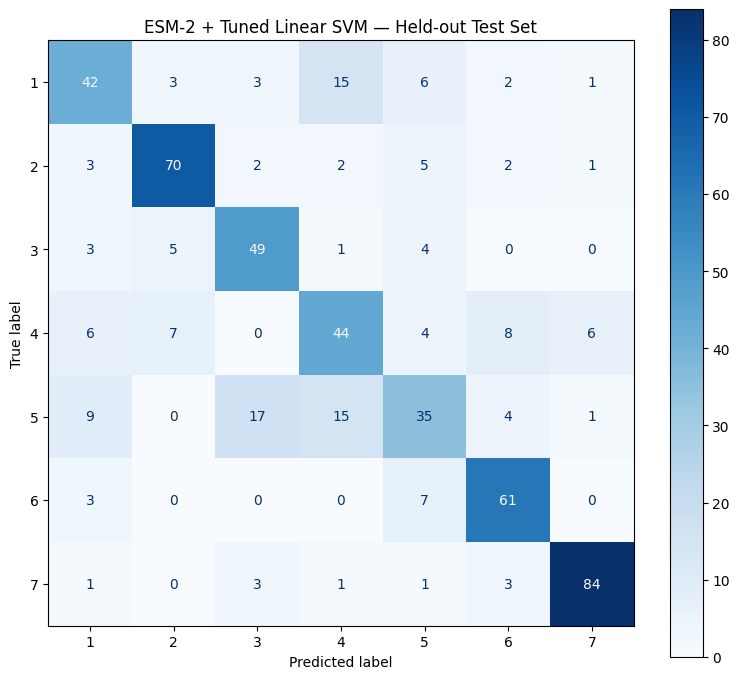

Saved files:
classification_report.csv - 705 bytes
classification_reports.json - 2874 bytes
confusion_matrix.csv - 242 bytes
confusion_matrix.png - 77662 bytes
esm2_svm_c_tuning.csv - 607 bytes
esm2_svm_tuning_summary.json - 1504 bytes
final_test_classification_report.csv - 705 bytes
final_test_confusion_matrix.csv - 242 bytes
final_test_confusion_matrix.png - 68722 bytes
final_test_metrics.json - 508 bytes
linear_svm_confusion_matrix.csv - 206 bytes
linear_svm_confusion_matrix.png - 51085 bytes
logistic_regression_confusion_matrix.csv - 206 bytes
logistic_regression_confusion_matrix.png - 54957 bytes
selected_esm2_svm_config.json - 529 bytes
validation_model_comparison.csv - 235 bytes

Metrics:
{
  "experiment": "ESM-2 embeddings + StandardScaler + Linear SVM",
  "embedding_model": "facebook/esm2_t12_35M_UR50D",
  "classifier": "LinearSVC",
  "selected_C": 2.0,
  "class_weight": "balanced",
  "selection_metric": "validation_macro_f1",
  "training_records": 2134,
  "test_records": 539,

In [26]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RESULTS_DIR = Path("/kaggle/working/esm2_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Use the corrected test embeddings and the final selected model.
test_data = np.load(
    "/kaggle/working/esm2_embeddings/test_embeddings.npz"
)
X_test = test_data["embeddings"]
y_test = test_data["labels"]

assert X_test.shape == (539, 480), X_test.shape
assert len(y_test) == 539
assert np.unique(X_test, axis=0).shape[0] > 1

y_pred = final_model.predict(X_test)
labels = [1, 2, 3, 4, 5, 6, 7]

metrics = {
    "experiment": "ESM-2 embeddings + StandardScaler + Linear SVM",
    "embedding_model": "facebook/esm2_t12_35M_UR50D",
    "classifier": "LinearSVC",
    "selected_C": 2.0,
    "class_weight": "balanced",
    "selection_metric": "validation_macro_f1",
    "training_records": 2134,
    "test_records": 539,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "macro_f1": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "weighted_f1": float(
        f1_score(y_test, y_pred, average="weighted")
    ),
    "test_used_for_model_selection": False,
    "random_state": 42
}

with open(RESULTS_DIR / "final_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).T.to_csv(
    RESULTS_DIR / "classification_report.csv"
)

cm = confusion_matrix(y_test, y_pred, labels=labels)
pd.DataFrame(
    cm,
    index=[f"True_{x}" for x in labels],
    columns=[f"Predicted_{x}" for x in labels]
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=True)
ax.set_title("ESM-2 + Tuned Linear SVM — Held-out Test Set")
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved files:")
for path in sorted(RESULTS_DIR.iterdir()):
    print(path.name, "-", path.stat().st_size, "bytes")

print("\nMetrics:")
print(json.dumps(metrics, indent=2))


In [27]:
from pathlib import Path

for folder in [
    Path("/kaggle/working/esm2_embeddings"),
    Path("/kaggle/working/esm2_results"),
]:
    print(f"\n--- {folder} ---")
    if folder.exists():
        for item in sorted(folder.iterdir()):
            if item.is_file():
                print(f"{item.name} ({item.stat().st_size / 1024**2:.2f} MB)")
            else:
                print(f"{item.name}/")
    else:
        print("Directory not found")


--- /kaggle/working/esm2_embeddings ---
test_embeddings.npz (0.92 MB)
train_embeddings.npz (3.00 MB)
validation_embeddings.npz (0.64 MB)

--- /kaggle/working/esm2_results ---
classification_report.csv (0.00 MB)
classification_reports.json (0.00 MB)
confusion_matrix.csv (0.00 MB)
confusion_matrix.png (0.07 MB)
esm2_svm_c_tuning.csv (0.00 MB)
esm2_svm_tuning_summary.json (0.00 MB)
final_test_classification_report.csv (0.00 MB)
final_test_confusion_matrix.csv (0.00 MB)
final_test_confusion_matrix.png (0.07 MB)
final_test_metrics.json (0.00 MB)
linear_svm_confusion_matrix.csv (0.00 MB)
linear_svm_confusion_matrix.png (0.05 MB)
logistic_regression_confusion_matrix.csv (0.00 MB)
logistic_regression_confusion_matrix.png (0.05 MB)
selected_esm2_svm_config.json (0.00 MB)
validation_model_comparison.csv (0.00 MB)


In [29]:

from pathlib import Path
import numpy as np

EMB_DIR = Path("/kaggle/working/esm2_embeddings")

for name in ["train", "validation", "test"]:
    path = EMB_DIR / f"{name}_embeddings.npz"
    print(f"\n--- {name.upper()} EMBEDDINGS ---")

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    with np.load(path, allow_pickle=True) as data:
        for key in data.files:
            arr = data[key]
            print(
                f"{key}: shape={arr.shape}, "
                f"dtype={arr.dtype}"
            )

            if key == "labels":
                print("Label counts:", dict(
                    zip(*np.unique(arr, return_counts=True))
                ))



--- TRAIN EMBEDDINGS ---
embeddings: shape=(1757, 480), dtype=float32
labels: shape=(1757,), dtype=int64
Label counts: {np.int64(1): np.int64(253), np.int64(2): np.int64(263), np.int64(3): np.int64(203), np.int64(4): np.int64(246), np.int64(5): np.int64(252), np.int64(6): np.int64(282), np.int64(7): np.int64(258)}
entries: shape=(1757,), dtype=object

--- VALIDATION EMBEDDINGS ---
embeddings: shape=(377, 480), dtype=float32
labels: shape=(377,), dtype=int64
Label counts: {np.int64(1): np.int64(60), np.int64(2): np.int64(64), np.int64(3): np.int64(41), np.int64(4): np.int64(55), np.int64(5): np.int64(52), np.int64(6): np.int64(57), np.int64(7): np.int64(48)}
entries: shape=(377,), dtype=object

--- TEST EMBEDDINGS ---
embeddings: shape=(539, 480), dtype=float32
labels: shape=(539,), dtype=int64
Label counts: {np.int64(1): np.int64(72), np.int64(2): np.int64(85), np.int64(3): np.int64(62), np.int64(4): np.int64(75), np.int64(5): np.int64(81), np.int64(6): np.int64(71), np.int64(7): np.i

Training: (1757, 480) (1757,)
Validation: (377, 480) (377,)
Training class counts: {np.int64(1): np.int64(253), np.int64(2): np.int64(263), np.int64(3): np.int64(203), np.int64(4): np.int64(246), np.int64(5): np.int64(252), np.int64(6): np.int64(282), np.int64(7): np.int64(258)}
Validation class counts: {np.int64(1): np.int64(60), np.int64(2): np.int64(64), np.int64(3): np.int64(41), np.int64(4): np.int64(55), np.int64(5): np.int64(52), np.int64(6): np.int64(57), np.int64(7): np.int64(48)}
Completed fraction=10%, seed=42, proteins=173
Completed fraction=10%, seed=123, proteins=173
Completed fraction=10%, seed=2026, proteins=173
Completed fraction=25%, seed=42, proteins=436
Completed fraction=25%, seed=123, proteins=436
Completed fraction=25%, seed=2026, proteins=436
Completed fraction=50%, seed=42, proteins=877
Completed fraction=50%, seed=123, proteins=877
Completed fraction=50%, seed=2026, proteins=877
Completed fraction=100%, seed=42, proteins=1757
Completed fraction=100%, seed=123,

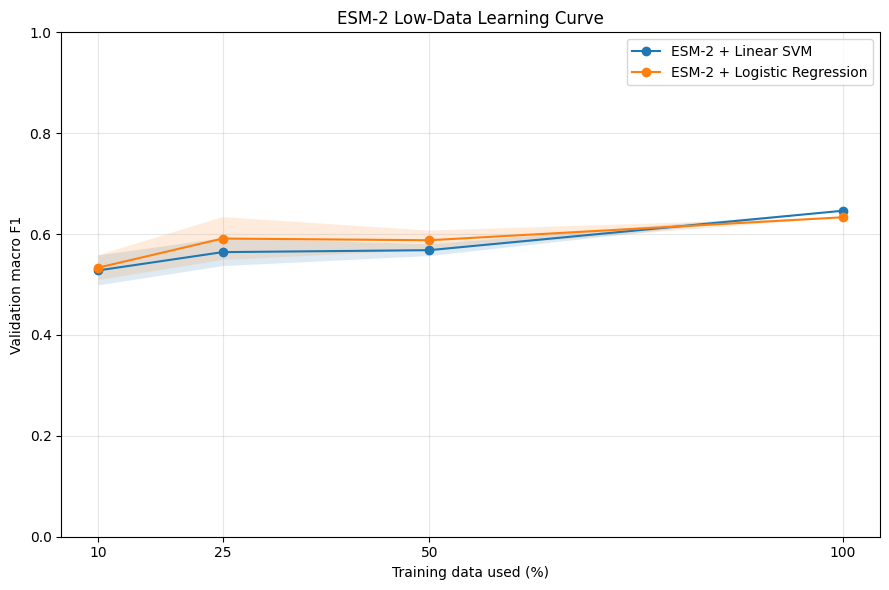


--- SUMMARY: MEAN ACROSS THREE SEEDS ---
 fraction  training_proteins                       model  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  accuracy_mean  weighted_f1_mean
     0.10                173          ESM-2 + Linear SVM         0.5281        0.0297                  0.5369         0.5402            0.5313
     0.10                173 ESM-2 + Logistic Regression         0.5336        0.0245                  0.5319         0.5367            0.5370
     0.25                436          ESM-2 + Linear SVM         0.5642        0.0278                  0.5651         0.5694            0.5672
     0.25                436 ESM-2 + Logistic Regression         0.5912        0.0426                  0.5910         0.5968            0.5965
     0.50                877          ESM-2 + Linear SVM         0.5681        0.0117                  0.5681         0.5774            0.5741
     0.50                877 ESM-2 + Logistic Regression         0.5878        0.0191               

In [30]:

# LOW-DATA LEARNING-CURVE EXPERIMENT
# Uses existing ESM-2 embeddings; does not retrain ESM-2.
# The test set is not loaded or evaluated in this experiment.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# ---------- Paths ----------
EMB_DIR = Path("/kaggle/working/esm2_embeddings")
OUT_DIR = Path("/kaggle/working/esm2_results/low_data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------- Load training and validation embeddings ----------
def load_embeddings(path):
    # These are the embedding files generated by your own notebook.
    with np.load(path, allow_pickle=True) as data:
        X = np.asarray(data["embeddings"], dtype=np.float32)
        y = np.asarray(data["labels"], dtype=np.int64)
    return X, y

X_train, y_train = load_embeddings(
    EMB_DIR / "train_embeddings.npz"
)
X_val, y_val = load_embeddings(
    EMB_DIR / "validation_embeddings.npz"
)

assert X_train.ndim == 2 and X_val.ndim == 2
assert X_train.shape[1] == X_val.shape[1] == 480
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert set(np.unique(y_train)) == set(np.unique(y_val))

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Training class counts:", dict(zip(
    *np.unique(y_train, return_counts=True)
)))
print("Validation class counts:", dict(zip(
    *np.unique(y_val, return_counts=True)
)))

# ---------- Experiment settings ----------
fractions = [0.10, 0.25, 0.50, 1.00]
seeds = [42, 123, 2026]

models = {
    "ESM-2 + Linear SVM": lambda: make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=2.0,
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    ),
    "ESM-2 + Logistic Regression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        )
    )
}

classes = np.sort(np.unique(y_train))
records = []

# Stratified sampling: preserve representation of every EC class.
# Existing cluster-aware train/validation separation remains intact.
for fraction in fractions:
    for seed in seeds:
        rng = np.random.default_rng(seed)
        selected = []

        for label in classes:
            class_indices = np.flatnonzero(y_train == label)
            n_take = max(1, int(np.floor(
                len(class_indices) * fraction
            )))
            n_take = min(n_take, len(class_indices))

            chosen = rng.choice(
                class_indices, size=n_take, replace=False
            )
            selected.extend(chosen.tolist())

        selected = np.array(selected, dtype=int)
        rng.shuffle(selected)

        X_sub = X_train[selected]
        y_sub = y_train[selected]

        for model_name, make_model in models.items():
            model = make_model()
            model.fit(X_sub, y_sub)
            pred = model.predict(X_val)

            records.append({
                "fraction": fraction,
                "training_proteins": len(selected),
                "seed": seed,
                "model": model_name,
                "accuracy": accuracy_score(y_val, pred),
                "balanced_accuracy": balanced_accuracy_score(
                    y_val, pred
                ),
                "macro_f1": f1_score(
                    y_val, pred, average="macro"
                ),
                "weighted_f1": f1_score(
                    y_val, pred, average="weighted"
                )
            })

        print(
            f"Completed fraction={fraction:.0%}, "
            f"seed={seed}, proteins={len(selected)}"
        )

# ---------- Save individual runs ----------
results = pd.DataFrame(records)
csv_path = OUT_DIR / "low_data_runs.csv"
results.to_csv(csv_path, index=False)

# ---------- Aggregate across random seeds ----------
summary = (
    results.groupby(["fraction", "training_proteins", "model"])
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        accuracy_mean=("accuracy", "mean"),
        weighted_f1_mean=("weighted_f1", "mean")
    )
    .reset_index()
)

summary_path = OUT_DIR / "low_data_summary.csv"
summary.to_csv(summary_path, index=False)

# ---------- Plot learning curves ----------
fig, ax = plt.subplots(figsize=(9, 6))

for model_name in models:
    subset = summary[summary["model"] == model_name].sort_values(
        "fraction"
    )
    x = subset["fraction"].to_numpy() * 100
    mean = subset["macro_f1_mean"].to_numpy()
    std = subset["macro_f1_std"].fillna(0).to_numpy()

    ax.plot(x, mean, marker="o", label=model_name)
    ax.fill_between(
        x,
        np.maximum(0, mean - std),
        np.minimum(1, mean + std),
        alpha=0.15
    )

ax.set_xlabel("Training data used (%)")
ax.set_ylabel("Validation macro F1")
ax.set_title("ESM-2 Low-Data Learning Curve")
ax.set_xticks([10, 25, 50, 100])
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

plot_path = OUT_DIR / "low_data_learning_curve.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("\n--- SUMMARY: MEAN ACROSS THREE SEEDS ---")
print(summary.round(4).to_string(index=False))

print("\nSaved files:")
print(csv_path)
print(summary_path)
print(plot_path)


In [33]:

from pathlib import Path
import numpy as np
import pandas as pd

# Inspect the saved training split
train_path = Path("/kaggle/working/train.csv")

if train_path.exists():
    train_df = pd.read_csv(train_path)
    print("Training CSV columns:")
    print(train_df.columns.tolist())
    print("\nFirst two rows:")
    print(train_df.head(2).to_string(index=False))
else:
    print("train.csv is not in /kaggle/working.")

# Inspect protein IDs stored alongside the embeddings
path = Path("/kaggle/working/esm2_embeddings/train_embeddings.npz")

with np.load(path, allow_pickle=True) as data:
    print("\nEmbedding archive keys:", data.files)
    if "entries" in data.files:
        entries = data["entries"]
        print("Entry count:", len(entries))
        print("First five entries:", entries[:5])


train.csv is not in /kaggle/working.

Embedding archive keys: ['embeddings', 'labels', 'entries']
Entry count: 1757
First five entries: ['A2RUC4' 'A5PLL7' 'O75828' 'O95571' 'O95881']


In [34]:

from pathlib import Path

roots = [
    Path("/kaggle/working"),
    Path("/kaggle/input"),
]

keywords = [
    "train.csv",
    "validation.csv",
    "test.csv",
    "sequence_cluster_membership.csv",
    "uniprot_clustered.csv",
    "split_metadata.json",
    "fasta_id_mapping.csv",
]

for root in roots:
    print(f"\n--- Searching {root} ---")
    if not root.exists():
        print("Directory not found")
        continue

    for path in root.rglob("*"):
        if path.is_file() and path.name in keywords:
            print(path)



--- Searching /kaggle/working ---

--- Searching /kaggle/input ---
/kaggle/input/datasets/s0ulraag/protein-set/validation.csv
/kaggle/input/datasets/s0ulraag/protein-set/train.csv
/kaggle/input/datasets/s0ulraag/protein-set/test.csv


In [35]:

import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")

print("Training shape:", train_df.shape)
print("Training columns:", train_df.columns.tolist())
print("\nTraining sample:")
print(train_df.head(3).to_string(index=False))

print("\nValidation shape:", val_df.shape)

# Inspect embedding IDs and compare them with the CSV.
with np.load(
    "/kaggle/working/esm2_embeddings/train_embeddings.npz",
    allow_pickle=True
) as data:
    embedding_entries = pd.Series(data["entries"].astype(str))

print("\nEmbedding entry examples:")
print(embedding_entries.head().tolist())

# Find likely accession/entry ID columns.
for col in train_df.columns:
    if col.lower() in ["entry", "accession", "uniprot_id", "id"]:
        csv_ids = set(train_df[col].astype(str))
        emb_ids = set(embedding_entries)
        print(f"\nID column: {col}")
        print("CSV IDs:", len(csv_ids))
        print("Embedding IDs:", len(emb_ids))
        print("IDs in both:", len(csv_ids & emb_ids))
        print("CSV IDs missing from embeddings:", len(csv_ids - emb_ids))
        print("Embedding IDs missing from CSV:", len(emb_ids - csv_ids))


Training shape: (1757, 35)
Training columns: ['Entry', 'Entry Name', 'Protein names', 'Organism', 'Organism (ID)', 'Length', 'Sequence', 'EC number', 'Annotation', 'Protein existence', 'GO', 'Gene Ontology (molecular function)', 'Gene Ontology (biological process)', 'Gene Ontology (cellular component)', 'retrieval_query', 'retrieval_ec_class', 'retrieval_timestamp_utc', 'source_url', 'Annotation score', 'complete_ec_numbers', 'top_level_classes', 'n_top_level_classes', 'label', 'annotation_class_status', 'retrieval_class_matches_annotation', 'sequence_clean', 'sequence_length_actual', 'ambiguous_residue_count', 'invalid_residue_count', 'has_invalid_characters', 'is_empty_sequence', 'exact_sequence_hash', 'is_exact_duplicate', 'length_matches_annotation', 'cluster_id']

Training sample:
 Entry  Entry Name                                                                                                                                                                       Protein names     

In [36]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")

train_df = pd.read_csv(DATA_DIR / "train.csv")

print("Training proteins:", len(train_df))
print("Distinct clusters:", train_df["cluster_id"].nunique())
print("Missing cluster IDs:", train_df["cluster_id"].isna().sum())

cluster_sizes = train_df.groupby("cluster_id").size()

print("\nCluster size summary:")
print(cluster_sizes.describe())

print("\nLargest clusters:")
print(cluster_sizes.sort_values(ascending=False).head(10))

# Check whether a cluster contains multiple EC labels.
cluster_label_counts = (
    train_df.groupby("cluster_id")["label"].nunique()
    if "label" in train_df.columns
    else train_df.groupby("cluster_id")["top_level_classes"].nunique()
)

print("\nClusters containing multiple labels:",
      int((cluster_label_counts > 1).sum()))
print("Total clusters:", len(cluster_label_counts))


Training proteins: 1757
Distinct clusters: 914
Missing cluster IDs: 0

Cluster size summary:
count    914.000000
mean       1.922319
std        2.765276
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       37.000000
dtype: float64

Largest clusters:
cluster_id
seq002508    37
seq002574    35
seq002428    27
seq002113    24
seq002020    23
seq002191    17
seq001067    17
seq002032    16
seq001405    15
seq001103    14
dtype: int64

Clusters containing multiple labels: 1
Total clusters: 914


Aligned training: (1757, 480)
Aligned validation: (377, 480)
EC classes: [1, 2, 3, 4, 5, 6, 7]
Training proteins: 1757
Training clusters: 914
Target=10%; seed=42; proteins=176/1757; clusters=116
Target=10%; seed=123; proteins=210/1757; clusters=100
Target=10%; seed=2026; proteins=176/1757; clusters=93
Target=25%; seed=42; proteins=440/1757; clusters=264
Target=25%; seed=123; proteins=440/1757; clusters=214
Target=25%; seed=2026; proteins=440/1757; clusters=225
Target=50%; seed=42; proteins=880/1757; clusters=494
Target=50%; seed=123; proteins=880/1757; clusters=444
Target=50%; seed=2026; proteins=879/1757; clusters=460
Target=100%; seed=42; proteins=1757/1757; clusters=914
Target=100%; seed=123; proteins=1757/1757; clusters=914
Target=100%; seed=2026; proteins=1757/1757; clusters=914


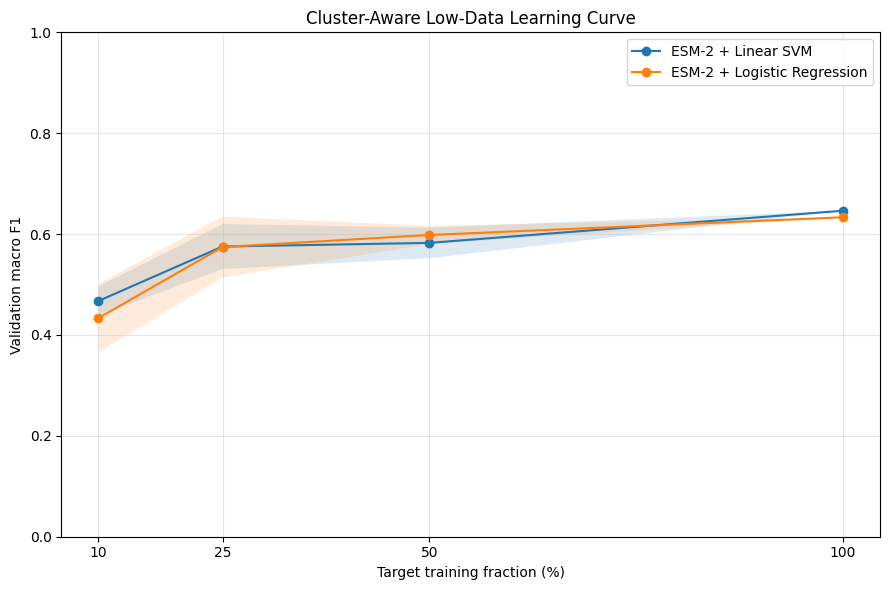


--- CLUSTER-AWARE SUMMARY ---
 fraction_target                       model  proteins_mean  clusters_mean  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  accuracy_mean  weighted_f1_mean
            0.10          ESM-2 + Linear SVM       187.3333       103.0000         0.4675        0.0288                  0.4735         0.4783            0.4716
            0.10 ESM-2 + Logistic Regression       187.3333       103.0000         0.4336        0.0678                  0.4518         0.4607            0.4415
            0.25          ESM-2 + Linear SVM       440.0000       234.3333         0.5753        0.0446                  0.5780         0.5862            0.5802
            0.25 ESM-2 + Logistic Regression       440.0000       234.3333         0.5743        0.0604                  0.5765         0.5818            0.5779
            0.50          ESM-2 + Linear SVM       879.6667       466.0000         0.5825        0.0303                  0.5820         0.5880            0.5843
   

In [37]:

# CLUSTER-AWARE LOW-DATA EXPERIMENT
# Uses existing ESM-2 embeddings and cluster IDs.
# Does not load or evaluate the test set.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")
EMB_DIR = Path("/kaggle/working/esm2_embeddings")
OUT_DIR = Path("/kaggle/working/esm2_results/cluster_low_data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Load split CSVs and their existing cluster assignments.
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")

assert train_df["cluster_id"].notna().all()
assert val_df["cluster_id"].notna().all()

# Labels should be the existing numeric top-level EC class labels.
LABEL_COL = "label"
assert LABEL_COL in train_df.columns, (
    f"Expected '{LABEL_COL}'. Available columns: {train_df.columns.tolist()}"
)

# Load embeddings and saved entry IDs.
def load_archive(name):
    with np.load(
        EMB_DIR / f"{name}_embeddings.npz",
        allow_pickle=True
    ) as data:
        return (
            np.asarray(data["embeddings"], dtype=np.float32),
            np.asarray(data["labels"], dtype=np.int64),
            np.asarray(data["entries"]).astype(str)
        )

X_train_raw, y_train_raw, train_entries = load_archive("train")
X_val_raw, y_val_raw, val_entries = load_archive("validation")

# Align embedding rows to CSV order using UniProt Entry IDs.
def align_to_csv(df, X, y, entries, split_name):
    if df["Entry"].astype(str).duplicated().any():
        raise ValueError(f"Duplicate Entry IDs in {split_name} CSV.")
    if len(set(entries)) != len(entries):
        raise ValueError(f"Duplicate embedding Entry IDs in {split_name}.")

    index_by_entry = {entry: i for i, entry in enumerate(entries)}
    csv_entries = df["Entry"].astype(str).tolist()

    missing = set(csv_entries) - set(index_by_entry)
    extra = set(index_by_entry) - set(csv_entries)
    if missing or extra:
        raise ValueError(
            f"{split_name} ID mismatch: missing={len(missing)}, "
            f"extra={len(extra)}"
        )

    order = np.array([index_by_entry[e] for e in csv_entries])
    X_aligned = X[order]
    y_aligned = y[order]
    y_csv = df[LABEL_COL].to_numpy(dtype=int)

    if not np.array_equal(y_aligned, y_csv):
        raise ValueError(
            f"{split_name} labels do not match embedding labels. "
            "Stop and inspect the label mapping."
        )

    return X_aligned, y_csv

X_train, y_train = align_to_csv(
    train_df, X_train_raw, y_train_raw, train_entries, "train"
)
X_val, y_val = align_to_csv(
    val_df, X_val_raw, y_val_raw, val_entries, "validation"
)

classes = np.sort(np.unique(y_train))
assert np.array_equal(classes, np.sort(np.unique(y_val)))

print("Aligned training:", X_train.shape)
print("Aligned validation:", X_val.shape)
print("EC classes:", classes.tolist())
print("Training proteins:", len(train_df))
print("Training clusters:", train_df["cluster_id"].nunique())

# Each cluster is sampled as an indivisible unit.
cluster_groups = {
    str(cluster): np.asarray(indices, dtype=int)
    for cluster, indices in train_df.groupby("cluster_id").groups.items()
}

cluster_labels = {}
for cluster, idx in cluster_groups.items():
    cluster_labels[cluster] = set(y_train[idx].tolist())

clusters_by_class = {
    label: [
        cluster for cluster, labels in cluster_labels.items()
        if label in labels
    ]
    for label in classes
}

for label, candidates in clusters_by_class.items():
    if not candidates:
        raise ValueError(f"No training cluster contains class {label}")

def sample_whole_clusters(fraction, seed):
    """Select whole clusters, target approximate protein fraction,
    and ensure all EC classes are represented where possible."""
    if fraction == 1.0:
        return np.arange(len(train_df)), list(cluster_groups.keys())

    rng = np.random.default_rng(seed)
    target_n = int(np.ceil(len(train_df) * fraction))
    selected_clusters = []

    # First choose one cluster containing each class.
    # A multi-label cluster may satisfy more than one class.
    class_order = list(classes)
    rng.shuffle(class_order)

    for label in class_order:
        if any(label in cluster_labels[c] for c in selected_clusters):
            continue

        candidates = [
            c for c in clusters_by_class[label]
            if c not in selected_clusters
        ]
        if candidates:
            selected_clusters.append(
                candidates[int(rng.integers(len(candidates)))]
            )

    # Add randomly ordered whole clusters until the target is reached.
    remaining = [
        c for c in cluster_groups if c not in selected_clusters
    ]
    rng.shuffle(remaining)

    selected_indices = np.concatenate([
        cluster_groups[c] for c in selected_clusters
    ]) if selected_clusters else np.array([], dtype=int)

    for cluster in remaining:
        if len(selected_indices) >= target_n:
            break
        selected_clusters.append(cluster)
        selected_indices = np.concatenate([
            selected_indices, cluster_groups[cluster]
        ])

    selected_indices = np.sort(selected_indices)

    represented = set(y_train[selected_indices].tolist())
    if represented != set(classes):
        raise ValueError(
            f"Not all classes represented at {fraction}: {represented}"
        )

    return selected_indices, selected_clusters

models = {
    "ESM-2 + Linear SVM": lambda: make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=2.0,
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    ),
    "ESM-2 + Logistic Regression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        )
    )
}

fractions = [0.10, 0.25, 0.50, 1.00]
seeds = [42, 123, 2026]
records = []

for fraction in fractions:
    for seed in seeds:
        idx, selected_clusters = sample_whole_clusters(fraction, seed)
        X_sub, y_sub = X_train[idx], y_train[idx]

        for model_name, make_model in models.items():
            model = make_model()
            model.fit(X_sub, y_sub)
            pred = model.predict(X_val)

            records.append({
                "fraction_target": fraction,
                "seed": seed,
                "training_proteins": len(idx),
                "training_clusters": len(selected_clusters),
                "model": model_name,
                "accuracy": accuracy_score(y_val, pred),
                "balanced_accuracy": balanced_accuracy_score(y_val, pred),
                "macro_f1": f1_score(y_val, pred, average="macro"),
                "weighted_f1": f1_score(
                    y_val, pred, average="weighted"
                )
            })

        print(
            f"Target={fraction:.0%}; seed={seed}; "
            f"proteins={len(idx)}/{len(train_df)}; "
            f"clusters={len(selected_clusters)}"
        )

results = pd.DataFrame(records)
results.to_csv(OUT_DIR / "cluster_low_data_runs.csv", index=False)

summary = (
    results.groupby(["fraction_target", "model"])
    .agg(
        proteins_mean=("training_proteins", "mean"),
        clusters_mean=("training_clusters", "mean"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        accuracy_mean=("accuracy", "mean"),
        weighted_f1_mean=("weighted_f1", "mean")
    )
    .reset_index()
)
summary.to_csv(OUT_DIR / "cluster_low_data_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
for model_name in models:
    sub = summary[summary["model"] == model_name].sort_values(
        "fraction_target"
    )
    x = sub["fraction_target"].to_numpy() * 100
    mean = sub["macro_f1_mean"].to_numpy()
    std = sub["macro_f1_std"].fillna(0).to_numpy()

    ax.plot(x, mean, marker="o", label=model_name)
    ax.fill_between(
        x, np.maximum(0, mean - std),
        np.minimum(1, mean + std), alpha=0.15
    )

ax.set_xlabel("Target training fraction (%)")
ax.set_ylabel("Validation macro F1")
ax.set_title("Cluster-Aware Low-Data Learning Curve")
ax.set_xticks([10, 25, 50, 100])
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    OUT_DIR / "cluster_low_data_learning_curve.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("\n--- CLUSTER-AWARE SUMMARY ---")
print(summary.round(4).to_string(index=False))
print("\nResults saved to:", OUT_DIR)


In [38]:

from pathlib import Path

roots = [
    Path("/kaggle/input/datasets/s0ulraag/protein-set"),
    Path("/kaggle/working"),
]

for root in roots:
    print(f"\n--- {root} ---")

    if not root.exists():
        print("Directory not found")
        continue

    for path in sorted(root.rglob("*")):
        if path.is_file() and path.suffix.lower() in {
            ".csv", ".tsv", ".fasta", ".fa", ".faa", ".json"
        }:
            print(f"{path} ({path.stat().st_size / 1024**2:.2f} MB)")



--- /kaggle/input/datasets/s0ulraag/protein-set ---
/kaggle/input/datasets/s0ulraag/protein-set/test.csv (1.72 MB)
/kaggle/input/datasets/s0ulraag/protein-set/train.csv (5.61 MB)
/kaggle/input/datasets/s0ulraag/protein-set/validation.csv (1.14 MB)

--- /kaggle/working ---
/kaggle/working/esm2_results/classification_report.csv (0.00 MB)
/kaggle/working/esm2_results/classification_reports.json (0.00 MB)
/kaggle/working/esm2_results/cluster_low_data/cluster_low_data_runs.csv (0.00 MB)
/kaggle/working/esm2_results/cluster_low_data/cluster_low_data_summary.csv (0.00 MB)
/kaggle/working/esm2_results/confusion_matrix.csv (0.00 MB)
/kaggle/working/esm2_results/esm2_svm_c_tuning.csv (0.00 MB)
/kaggle/working/esm2_results/esm2_svm_tuning_summary.json (0.00 MB)
/kaggle/working/esm2_results/final_test_classification_report.csv (0.00 MB)
/kaggle/working/esm2_results/final_test_confusion_matrix.csv (0.00 MB)
/kaggle/working/esm2_results/final_test_metrics.json (0.00 MB)
/kaggle/working/esm2_results

In [39]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")

train = pd.read_csv(DATA_DIR / "train.csv")
val = pd.read_csv(DATA_DIR / "validation.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

all_data = pd.concat([train, val, test], ignore_index=True)

print("Total records:", len(all_data))
print("Unique UniProt accessions:", all_data["Entry"].nunique())
print("Duplicate accessions:", all_data["Entry"].duplicated().sum())

print("\nRelevant columns:")
print([
    c for c in all_data.columns
    if c.lower() in {
        "entry", "sequence", "sequence_clean", "label",
        "top_level_classes", "cluster_id", "ec number"
    }
])

print("\nEC class counts:")
print(all_data["label"].value_counts().sort_index())

print("\nSequence lengths:")
print(all_data["sequence_clean"].str.len().describe())


Total records: 2673
Unique UniProt accessions: 2673
Duplicate accessions: 0

Relevant columns:
['Entry', 'Sequence', 'EC number', 'top_level_classes', 'label', 'sequence_clean', 'cluster_id']

EC class counts:
label
1    385
2    412
3    306
4    376
5    385
6    410
7    399
Name: count, dtype: int64

Sequence lengths:
count    2673.000000
mean      612.280584
std       353.660054
min        37.000000
25%       354.000000
50%       514.000000
75%       764.000000
max      1957.000000
Name: sequence_clean, dtype: float64


In [40]:

import requests
import pandas as pd

url = "https://rest.uniprot.org/uniprotkb/search"

params = {
    "query": "reviewed:true AND (ec:1 OR ec:2 OR ec:3 OR ec:4 OR ec:5 OR ec:6 OR ec:7)",
    "format": "tsv",
    "fields": "accession,protein_name,organism_name,length,sequence,ec",
    "size": 5,
}

try:
    response = requests.get(url, params=params, timeout=30)
    print("HTTP status:", response.status_code)
    print("Response preview:")
    print(response.text[:1500])
except Exception as exc:
    print(type(exc).__name__, str(exc))


HTTP status: 200
Response preview:
Entry	Protein names	Organism	Length	Sequence	EC number
Q08426	Peroxisomal bifunctional enzyme (PBE) (PBFE) (L-bifunctional protein) (LBP) (Multifunctional enzyme 1) (MFE1) [Includes: Enoyl-CoA hydratase/3,2-trans-enoyl-CoA isomerase (EC 4.2.1.17) (EC 5.3.3.8); 3-hydroxyacyl-CoA dehydrogenase (EC 1.1.1.35)]	Homo sapiens (Human)	723	MAEYTRLHNALALIRLRNPPVNAISTTLLRDIKEGLQKAVIDHTIKAIVICGAEGKFSAGADIRGFSAPRTFGLTLGHVVDEIQRNEKPVVAAIQGMAFGGGLELALGCHYRIAHAEAQVGLPEVTLGLLPGARGTQLLPRLTGVPAALDLITSGRRILADEALKLGILDKVVNSDPVEEAIRFAQRVSDQPLESRRLCNKPIQSLPNMDSIFSEALLKMRRQHPGCLAQEACVRAVQAAVQYPYEVGIKKEEELFLYLLQSGQARALQYAFFAERKANKWSTPSGASWKTASARPVSSVGVVGLGTMGRGIVISFARARIPVIAVDSDKNQLATANKMITSVLEKEASKMQQSGHPWSGPKPRLTSSVKELGGVDLVIEAVFEEMSLKKQVFAELSAVCKPEAFLCTNTSALDVDEIASSTDRPHLVIGTHFFSPAHVMKLLEVIPSQYSSPTTIATVMNLSKKIKKIGVVVGNCFGFVGNRMLNPYYNQAYFLLEEGSKPEEVDQVLEEFGFKMGPFRVSDLAGLDVGWKSRKGQGLTGPTLLPGTPARKRGNRRYCPIPDVLCELGRFGQKTGKGWYQYDKPLGRIHKPDPWLSKFLSRYRKTHHIEPRTISQDEILERCLYSLINEAF

In [42]:

import requests
import pandas as pd
from io import StringIO

url = "https://rest.uniprot.org/uniprotkb/search"

params = {
    "query": "reviewed:true",
    "format": "tsv",
    "fields": "accession,protein_name,organism_name,length,sequence,ec",
    "size": 5,
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)
print("URL:", response.url)
print("Response preview:")
print(response.text[:1000])

if response.ok:
    preview = pd.read_csv(StringIO(response.text), sep="\t")
    print("\nColumns:", preview.columns.tolist())
    print(preview.head(3).to_string(index=False))


HTTP status: 200
URL: https://rest.uniprot.org/uniprotkb/search?query=reviewed%3Atrue&format=tsv&fields=accession%2Cprotein_name%2Corganism_name%2Clength%2Csequence%2Cec&size=5
Response preview:
Entry	Protein names	Organism	Length	Sequence	EC number
A0A0C5B5G6	Mitochondrial-derived peptide MOTS-c (Mitochondrial open reading frame of the 12S rRNA-c)	Homo sapiens (Human)	16	MRWQEMGYIFYPRKLR	
A0A1B0GTW7	Ciliated left-right organizer metallopeptidase (EC 3.4.24.-) (Leishmanolysin-like peptidase 2)	Homo sapiens (Human)	788	MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKSRSSSLTLPSSRDPQPLRIQSCYLGDHISDGAWDPEGEGMRGGSRALAAVREATQRIQAVLAVQGPLLLSRDPAQYCHAVWGDPDSPNYHRCSLLNPGYKGESCLGAKIPDTHLRGYALWPEQGPPQLVQPDGPGVQNTDFLLYVRVAHTSKCHQETVSLCCPGWSTAAQSQLTAALTSWAQRRGFVMLPRLCLKLLGSSNLPTLASQSIRITGPSVIAYAACCQLDSEDRPLAGTIVYCAQHLTSPSLSHSDIVMATLHELLHALGFSGQLFKKWRDCPSGFSVRENCSTRQLVTRQDEWGQLLLTTPAVSLSLAKHLGVSGASLGVPLEEEEGLLSSHWEARLLQGSLMTATFDGAQRTRLDPITLAAFKDSGWYQVNHSAAEELLWGQGSGPEFGLVTTCGTGSSDFFCTGSGLGCHYLHLDKGSCSS

In [44]:

import requests
import pandas as pd
import re
import time
from io import StringIO
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")
OUT_DIR = Path("/kaggle/working/enzyme_candidates")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# All existing accessions must be excluded.
existing = set()
for split in ["train.csv", "validation.csv", "test.csv"]:
    df = pd.read_csv(DATA_DIR / split, usecols=["Entry"])
    existing.update(df["Entry"].astype(str).str.strip())

API = "https://rest.uniprot.org/uniprotkb/search"
FIELDS = "accession,protein_name,organism_name,length,sequence,ec"
PAGE_SIZE = 500
MAX_RECORDS = 5000

# Specifically query proteins with EC annotations in classes 1–7.
query = (
    "reviewed:true AND "
    "(ec:1.* OR ec:2.* OR ec:3.* OR ec:4.* OR "
    "ec:5.* OR ec:6.* OR ec:7.*)"
)

session = requests.Session()
params = {
    "query": query,
    "format": "tsv",
    "fields": FIELDS,
    "size": PAGE_SIZE,
}

records = []
url = API
first_request = True

while url and len(records) < MAX_RECORDS:
    response = session.get(
        url,
        params=params if first_request else None,
        timeout=60
    )

    if not response.ok:
        print("HTTP status:", response.status_code)
        print("Response:", response.text[:1500])
        response.raise_for_status()

    first_request = False
    page = pd.read_csv(StringIO(response.text), sep="\t")

    if page.empty:
        break

    records.extend(page.to_dict("records"))
    print("Records retrieved so far:", len(records))

    next_url = None
    for part in response.headers.get("Link", "").split(","):
        if 'rel="next"' in part:
            match = re.search(r"<([^>]+)>", part)
            if match:
                next_url = match.group(1)
                break

    url = next_url
    if url:
        time.sleep(0.2)

raw = pd.DataFrame(records).drop_duplicates("Entry").copy()
print("\nUnique downloaded records:", len(raw))

# Exclude the complete original dataset.
raw = raw[~raw["Entry"].astype(str).isin(existing)].copy()
print("After accession exclusion:", len(raw))

def get_top_level_classes(value):
    if pd.isna(value):
        return set()
    ec_numbers = re.findall(
        r"(?<!\d)([1-7])\.\d+\.\d+\.\d+", str(value)
    )
    return set(ec_numbers)

raw["top_level_set"] = raw["EC number"].apply(
    get_top_level_classes
)

# Keep records whose annotated ECs all belong to one top-level class.
raw = raw[raw["top_level_set"].map(len) == 1].copy()
raw["external_label"] = raw["top_level_set"].map(
    lambda values: int(next(iter(values)))
)

raw["Length"] = pd.to_numeric(raw["Length"], errors="coerce")
raw = raw[
    raw["Sequence"].notna()
    & raw["Sequence"].str.fullmatch(
        r"[ACDEFGHIKLMNPQRSTVWY]+", na=False
    )
    & (raw["Length"] >= 50)
].copy()

raw = raw.drop_duplicates("Entry").reset_index(drop=True)
raw = raw.drop(columns=["top_level_set"])

# Final accession-overlap check.
assert not set(raw["Entry"].astype(str)) & existing

output = OUT_DIR / "external_reviewed_enzyme_pool_v2.csv"
raw.to_csv(output, index=False)

print("\nFINAL EXTERNAL POOL:", len(raw))
print("\nClass counts:")
print(raw["external_label"].value_counts().sort_index().to_string())
print("\nSaved to:", output)
print("\nFirst five accessions:")
print(raw[["Entry", "Length", "EC number", "external_label"]].head())


Records retrieved so far: 500

Unique downloaded records: 500
After accession exclusion: 185

FINAL EXTERNAL POOL: 41

Class counts:
external_label
2    19
3    17
4     2
5     2
6     1

Saved to: /kaggle/working/enzyme_candidates/external_reviewed_enzyme_pool_v2.csv

First five accessions:
    Entry  Length                             EC number  external_label
0  P08263     222           1.11.1.-; 2.5.1.18; 5.3.3.-               2
1  O14880     152           1.11.1.-; 2.5.1.-; 4.4.1.20               4
2  O75503     358                     2.3.1.-; 3.1.2.22               3
3  P04062     536  2.4.1.-; 3.2.1.-; 3.2.1.45; 3.2.1.46               3
4  P17812     591                      3.5.1.-; 6.3.4.2               6


In [46]:

import requests
import pandas as pd
from io import StringIO

url = "https://rest.uniprot.org/uniprotkb/search"

tests = [
    ("Reviewed proteins", "reviewed:true"),
    ("Reviewed proteins with EC 1", "reviewed:true AND ec:1"),
    ("Reviewed proteins with EC 2", "reviewed:true AND ec:2"),
]

for label, query in tests:
    print(f"\n--- {label} ---")

    response = requests.get(
        url,
        params={
            "query": query,
            "format": "tsv",
            "fields": "accession,protein_name,length,sequence,ec",
            "size": 5,
        },
        timeout=60,
    )

    print("HTTP:", response.status_code)

    if response.ok:
        df = pd.read_csv(StringIO(response.text), sep="\t")
        print("Returned:", len(df))
        print(df[["Entry", "Length", "EC number"]].to_string(index=False))
    else:
        print(response.text[:500])



--- Reviewed proteins ---
HTTP: 200
Returned: 5
     Entry  Length EC number
A0A0C5B5G6      16       NaN
A0A1B0GTW7     788  3.4.24.-
    A0JNW5    1464       NaN
    A0JP26     581       NaN
    A0PK11     232       NaN

--- Reviewed proteins with EC 1 ---
HTTP: 200
Returned: 5
 Entry  Length                                                                                                         EC number
P17516     323                                 1.1.1.-; 1.1.1.209; 1.1.1.210; 1.1.1.225; 1.1.1.357; 1.1.1.51; 1.1.1.53; 1.1.1.62
Q04828     323 1.1.1.-; 1.1.1.112; 1.1.1.149; 1.1.1.209; 1.1.1.210; 1.1.1.270; 1.1.1.357; 1.1.1.51; 1.1.1.53; 1.1.1.62; 1.3.1.20
O14756     317                                                               1.1.1.105; 1.1.1.209; 1.1.1.239; 1.1.1.53; 1.1.1.62
P14550     325                                                         1.1.1.19; 1.1.1.2; 1.1.1.20; 1.1.1.372; 1.1.1.54; 1.6.-.-
Q9HBI6     524                                                           

In [47]:

import requests
import pandas as pd
import re
import time
from io import StringIO
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")
OUT_DIR = Path("/kaggle/working/enzyme_candidates")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Exclude every protein already in the project.
existing = set()
for filename in ["train.csv", "validation.csv", "test.csv"]:
    df = pd.read_csv(DATA_DIR / filename, usecols=["Entry"])
    existing.update(df["Entry"].astype(str).str.strip())

API = "https://rest.uniprot.org/uniprotkb/search"
FIELDS = "accession,protein_name,organism_name,length,sequence,ec"
PAGE_SIZE = 500
MAX_PER_CLASS = 1000

def parse_ec_classes(value):
    if pd.isna(value):
        return set()

    # Accept complete and partial EC numbers:
    # e.g. 1.1.1.-, 1.1.1.209, 3.4.-.-
    matches = re.findall(
        r"(?<!\d)([1-7])\.(?:\d+|-)(?:\.(?:\d+|-))?(?:\.(?:\d+|-))?",
        str(value)
    )
    return set(matches)

session = requests.Session()
collected = []

for ec_class in range(1, 8):
    print(f"\nCollecting EC class {ec_class}...")

    params = {
        "query": f"reviewed:true AND ec:{ec_class}",
        "format": "tsv",
        "fields": FIELDS,
        "size": PAGE_SIZE,
    }

    url = API
    first_request = True
    class_records = []
    seen_page_urls = set()

    while url and len(class_records) < MAX_PER_CLASS:
        if url in seen_page_urls:
            break
        seen_page_urls.add(url)

        response = session.get(
            url,
            params=params if first_request else None,
            timeout=60
        )
        response.raise_for_status()
        first_request = False

        page = pd.read_csv(StringIO(response.text), sep="\t")
        if page.empty:
            break

        class_records.extend(page.to_dict("records"))

        next_url = None
        for part in response.headers.get("Link", "").split(","):
            if 'rel="next"' in part:
                match = re.search(r"<([^>]+)>", part)
                if match:
                    next_url = match.group(1)
                    break

        url = next_url
        if url:
            time.sleep(0.2)

    page_df = pd.DataFrame(class_records)
    if page_df.empty:
        print("No records returned.")
        continue

    page_df = page_df.drop_duplicates("Entry")
    page_df = page_df[
        ~page_df["Entry"].astype(str).isin(existing)
    ].copy()

    page_df["ec_classes"] = page_df["EC number"].apply(parse_ec_classes)

    # Retain only proteins whose recorded EC numbers all belong
    # to this one top-level class.
    page_df = page_df[
        page_df["ec_classes"].apply(
            lambda classes: len(classes) == 1
            and ec_class in classes
        )
    ].copy()

    page_df["Length"] = pd.to_numeric(
        page_df["Length"], errors="coerce"
    )
    page_df = page_df[
        page_df["Sequence"].notna()
        & page_df["Sequence"].str.fullmatch(
            r"[ACDEFGHIKLMNPQRSTVWY]+", na=False
        )
        & (page_df["Length"] >= 50)
    ].copy()

    page_df["external_label"] = ec_class
    page_df = page_df.drop(columns=["ec_classes"])
    collected.append(page_df)

    print("Retained:", len(page_df))

if not collected:
    raise RuntimeError("No external proteins were collected.")

pool = pd.concat(collected, ignore_index=True)
pool = pool.drop_duplicates("Entry").reset_index(drop=True)

assert not (set(pool["Entry"].astype(str)) & existing)

output = OUT_DIR / "external_reviewed_enzyme_pool_v4.csv"
pool.to_csv(output, index=False)

print("\nFinal pool size:", len(pool))
print("\nClass counts:")
print(pool["external_label"].value_counts().sort_index().to_string())
print("\nUnique accessions:", pool["Entry"].nunique())
print("Saved to:", output)



Retained: 0

Retained: 0

Retained: 0

Retained: 0

Retained: 0

Retained: 0

Retained: 0

Final pool size: 0

Class counts:
Series([], )

Unique accessions: 0
Saved to: /kaggle/working/enzyme_candidates/external_reviewed_enzyme_pool_v4.csv


In [48]:

import requests
import pandas as pd
from io import StringIO
import re

url = "https://rest.uniprot.org/uniprotkb/search"

response = requests.get(
    url,
    params={
        "query": "reviewed:true AND ec:1",
        "format": "tsv",
        "fields": "accession,protein_name,length,sequence,ec",
        "size": 10,
    },
    timeout=60,
)

print("HTTP:", response.status_code)
response.raise_for_status()

sample = pd.read_csv(StringIO(response.text), sep="\t")

def parser(value):
    if pd.isna(value):
        return set()
    return set(re.findall(r"(?<!\d)([1-7])\.", str(value)))

for _, row in sample.iterrows():
    print(
        "Entry:", row["Entry"],
        "| EC:", repr(row["EC number"]),
        "| parsed classes:", parser(row["EC number"])
    )


HTTP: 200
Entry: P17516 | EC: '1.1.1.-; 1.1.1.209; 1.1.1.210; 1.1.1.225; 1.1.1.357; 1.1.1.51; 1.1.1.53; 1.1.1.62' | parsed classes: {'1'}
Entry: Q04828 | EC: '1.1.1.-; 1.1.1.112; 1.1.1.149; 1.1.1.209; 1.1.1.210; 1.1.1.270; 1.1.1.357; 1.1.1.51; 1.1.1.53; 1.1.1.62; 1.3.1.20' | parsed classes: {'1', '3'}
Entry: O14756 | EC: '1.1.1.105; 1.1.1.209; 1.1.1.239; 1.1.1.53; 1.1.1.62' | parsed classes: {'1'}
Entry: P14550 | EC: '1.1.1.19; 1.1.1.2; 1.1.1.20; 1.1.1.372; 1.1.1.54; 1.6.-.-' | parsed classes: {'1', '6'}
Entry: Q9HBI6 | EC: '1.14.14.1; 1.14.14.78; 1.14.14.79; 1.14.14.80' | parsed classes: {'1'}
Entry: P42330 | EC: '1.1.1.-; 1.1.1.188; 1.1.1.210; 1.1.1.239; 1.1.1.357; 1.1.1.53; 1.1.1.62; 1.1.1.64' | parsed classes: {'1'}
Entry: C9JRZ8 | EC: '1.1.1.-; 1.1.1.216; 1.1.1.300; 1.1.1.54; 1.1.1.64' | parsed classes: {'1'}
Entry: P49189 | EC: '1.2.1.19; 1.2.1.3; 1.2.1.46; 1.2.1.47' | parsed classes: {'1', '2'}
Entry: P52895 | EC: '1.1.1.112; 1.1.1.209; 1.1.1.357; 1.1.1.51; 1.1.1.62; 1.3.1.20' |

In [49]:

import requests
import pandas as pd
import re
import time
from io import StringIO
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")
OUT_DIR = Path("/kaggle/working/enzyme_candidates")
OUT_DIR.mkdir(parents=True, exist_ok=True)

existing = set()
for filename in ["train.csv", "validation.csv", "test.csv"]:
    df = pd.read_csv(DATA_DIR / filename, usecols=["Entry"])
    existing.update(df["Entry"].astype(str).str.strip())

API = "https://rest.uniprot.org/uniprotkb/search"
FIELDS = "accession,protein_name,organism_name,length,sequence,ec"
session = requests.Session()

def parse_classes(value):
    if pd.isna(value):
        return set()
    return set(re.findall(r"(?<!\d)([1-7])\.", str(value)))

frames = []

for ec_class in range(1, 8):
    response = session.get(
        API,
        params={
            "query": f"reviewed:true AND ec:{ec_class}",
            "format": "tsv",
            "fields": FIELDS,
            "size": 100,
        },
        timeout=60,
    )
    response.raise_for_status()
    page = pd.read_csv(StringIO(response.text), sep="\t")

    if page.empty:
        continue

    page = page.drop_duplicates("Entry")
    page = page[~page["Entry"].astype(str).isin(existing)].copy()

    page["annotated_classes"] = page["EC number"].apply(parse_classes)
    page = page[
        page["annotated_classes"].apply(lambda x: ec_class in x)
    ].copy()

    page["Length"] = pd.to_numeric(page["Length"], errors="coerce")
    page = page[
        page["Sequence"].notna()
        & page["Sequence"].str.fullmatch(
            r"[ACDEFGHIKLMNPQRSTVWY]+", na=False
        )
        & (page["Length"] >= 50)
    ].copy()

    page["queried_class"] = ec_class
    page["annotation_ambiguous"] = (
        page["annotated_classes"].apply(len) > 1
    )
    page["annotated_classes"] = page["annotated_classes"].apply(
        lambda x: ",".join(sorted(x))
    )

    frames.append(page)
    print(f"Class {ec_class}: retained {len(page)} records")
    time.sleep(0.2)

if not frames:
    raise RuntimeError("No records retrieved.")

pool = pd.concat(frames, ignore_index=True)
pool = pool.drop_duplicates("Entry").reset_index(drop=True)

assert not (set(pool["Entry"].astype(str)) & existing)

output = OUT_DIR / "external_reviewed_enzyme_pool_v5.csv"
pool.to_csv(output, index=False)

print("\nUnique external proteins:", pool["Entry"].nunique())
print("\nCounts by queried class:")
print(pool.groupby("queried_class")["Entry"].nunique().to_string())
print("\nAmbiguous annotation flags:")
print(pool["annotation_ambiguous"].value_counts().to_string())
print("\nSaved:", output)


Class 1: retained 0 records
Class 2: retained 0 records
Class 3: retained 0 records
Class 4: retained 0 records
Class 5: retained 0 records
Class 6: retained 0 records
Class 7: retained 0 records

Unique external proteins: 0

Counts by queried class:
Series([], )

Ambiguous annotation flags:
Series([], )

Saved: /kaggle/working/enzyme_candidates/external_reviewed_enzyme_pool_v5.csv


In [50]:

import requests
import pandas as pd
from io import StringIO
import re

url = "https://rest.uniprot.org/uniprotkb/search"

response = requests.get(
    url,
    params={
        "query": "reviewed:true AND ec:1",
        "format": "tsv",
        "fields": "accession,protein_name,length,sequence,ec",
        "size": 5,
    },
    timeout=60,
)
response.raise_for_status()

df = pd.read_csv(StringIO(response.text), sep="\t")

print("Returned records:", len(df))
print("Columns:", df.columns.tolist())

for _, row in df.iterrows():
    ec = str(row["EC number"])
    classes = set(re.findall(r"(?<!\d)([1-7])\.", ec))

    seq = row["Sequence"]
    valid_sequence = (
        isinstance(seq, str)
        and bool(re.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY]+", seq))
    )

    print({
        "Entry": row["Entry"],
        "EC": ec,
        "Parsed classes": classes,
        "Length": row["Length"],
        "Sequence valid": valid_sequence,
        "Class 1 matches": "1" in classes,
    })


Returned records: 5
Columns: ['Entry', 'Protein names', 'Length', 'Sequence', 'EC number']
{'Entry': 'P17516', 'EC': '1.1.1.-; 1.1.1.209; 1.1.1.210; 1.1.1.225; 1.1.1.357; 1.1.1.51; 1.1.1.53; 1.1.1.62', 'Parsed classes': {'1'}, 'Length': 323, 'Sequence valid': True, 'Class 1 matches': True}
{'Entry': 'Q04828', 'EC': '1.1.1.-; 1.1.1.112; 1.1.1.149; 1.1.1.209; 1.1.1.210; 1.1.1.270; 1.1.1.357; 1.1.1.51; 1.1.1.53; 1.1.1.62; 1.3.1.20', 'Parsed classes': {'1', '3'}, 'Length': 323, 'Sequence valid': True, 'Class 1 matches': True}
{'Entry': 'O14756', 'EC': '1.1.1.105; 1.1.1.209; 1.1.1.239; 1.1.1.53; 1.1.1.62', 'Parsed classes': {'1'}, 'Length': 317, 'Sequence valid': True, 'Class 1 matches': True}
{'Entry': 'P14550', 'EC': '1.1.1.19; 1.1.1.2; 1.1.1.20; 1.1.1.372; 1.1.1.54; 1.6.-.-', 'Parsed classes': {'1', '6'}, 'Length': 325, 'Sequence valid': True, 'Class 1 matches': True}
{'Entry': 'Q9HBI6', 'EC': '1.14.14.1; 1.14.14.78; 1.14.14.79; 1.14.14.80', 'Parsed classes': {'1'}, 'Length': 524, 'Seque

In [51]:

import requests
import pandas as pd
import time
from io import StringIO
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/s0ulraag/protein-set")
OUT_DIR = Path("/kaggle/working/enzyme_candidates")
OUT_DIR.mkdir(parents=True, exist_ok=True)

existing = set()
for filename in ["train.csv", "validation.csv", "test.csv"]:
    df = pd.read_csv(DATA_DIR / filename, usecols=["Entry"])
    existing.update(df["Entry"].astype(str).str.strip())

API = "https://rest.uniprot.org/uniprotkb/search"
FIELDS = "accession,protein_name,organism_name,length,sequence,ec"

frames = []

for ec_class in range(1, 8):
    response = requests.get(
        API,
        params={
            "query": f"reviewed:true AND ec:{ec_class}",
            "format": "tsv",
            "fields": FIELDS,
            "size": 100,
        },
        timeout=60,
    )
    response.raise_for_status()

    df = pd.read_csv(StringIO(response.text), sep="\t")
    df["queried_class"] = ec_class

    # First retain valid records, before excluding existing accessions.
    df["Length"] = pd.to_numeric(df["Length"], errors="coerce")
    df = df[
        df["Sequence"].notna()
        & df["Sequence"].str.fullmatch(
            r"[ACDEFGHIKLMNPQRSTVWY]+", na=False
        )
        & (df["Length"] >= 50)
    ].copy()

    print(
        f"Class {ec_class}: valid raw records={len(df)}, "
        f"already in project={(df['Entry'].astype(str).isin(existing)).sum()}"
    )

    frames.append(df)
    time.sleep(0.2)

raw_pool = pd.concat(frames, ignore_index=True)
raw_pool = raw_pool.drop_duplicates("Entry").reset_index(drop=True)

# Exclude the existing dataset only after collecting the raw records.
external = raw_pool[
    ~raw_pool["Entry"].astype(str).isin(existing)
].copy()

raw_path = OUT_DIR / "external_pool_raw_v6.csv"
external.to_csv(raw_path, index=False)

print("\nRaw external pool size:", len(external))
print("Unique accessions:", external["Entry"].nunique())
print("Saved to:", raw_path)
print("\nRecords by queried class:")
print(external["queried_class"].value_counts().sort_index().to_string())


Class 1: valid raw records=95, already in project=85
Class 2: valid raw records=100, already in project=53
Class 3: valid raw records=100, already in project=41
Class 4: valid raw records=100, already in project=76
Class 5: valid raw records=100, already in project=80
Class 6: valid raw records=100, already in project=91
Class 7: valid raw records=100, already in project=77

Raw external pool size: 179
Unique accessions: 179
Saved to: /kaggle/working/enzyme_candidates/external_pool_raw_v6.csv

Records by queried class:
queried_class
1    10
2    47
3    58
4    23
5    10
6     8
7    23


In [52]:

import pandas as pd
import re
from pathlib import Path

pool_path = Path(
    "/kaggle/working/enzyme_candidates/external_pool_raw_v6.csv"
)
pool = pd.read_csv(pool_path)

def extract_classes(ec_value):
    if pd.isna(ec_value):
        return set()
    # Handles multiple and partially specified EC annotations.
    return set(re.findall(r"(?<!\d)([1-7])\.", str(ec_value)))

pool["annotated_classes"] = pool["EC number"].apply(extract_classes)
pool["num_top_level_classes"] = pool["annotated_classes"].apply(len)

# Keep proteins with exactly one annotated top-level class
# for the initial external classification evaluation.
evaluation = pool[pool["num_top_level_classes"] == 1].copy()
evaluation["true_label"] = evaluation["annotated_classes"].apply(
    lambda classes: int(next(iter(classes)))
)

ambiguous = pool[pool["num_top_level_classes"] > 1].copy()
unlabelled = pool[pool["num_top_level_classes"] == 0].copy()

print("Total external proteins:", len(pool))
print("Unambiguous proteins:", len(evaluation))
print("Multi-class proteins excluded from primary scoring:", len(ambiguous))
print("No parseable top-level EC class:", len(unlabelled))

print("\nGround-truth class counts:")
print(evaluation["true_label"].value_counts().sort_index().to_string())

print("\nExample unambiguous records:")
print(
    evaluation[["Entry", "Length", "EC number", "true_label"]]
    .head(10)
    .to_string(index=False)
)

out = Path("/kaggle/working/enzyme_candidates")
evaluation.drop(columns=["annotated_classes"]).to_csv(
    out / "external_evaluation_set.csv", index=False
)
ambiguous.to_csv(out / "external_ambiguous_annotations.csv", index=False)

print("\nSaved primary evaluation set and ambiguous records.")


Total external proteins: 179
Unambiguous proteins: 2
Multi-class proteins excluded from primary scoring: 177
No parseable top-level EC class: 0

Ground-truth class counts:
true_label
1    2

Example unambiguous records:
 Entry  Length                                                     EC number  true_label
Q99714     261 1.1.1.159; 1.1.1.178; 1.1.1.239; 1.1.1.35; 1.1.1.53; 1.1.1.62           1
Q6N021    2002                                                    1.14.11.80           1

Saved primary evaluation set and ambiguous records.
